# STEP 1: Import Data


In [1]:

# Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tampilan
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Library berhasil diimport!")


Library berhasil diimport!


In [2]:
# Pemeriksaan Lingkungan Eksekusi (Google Colab vs Lokal)
try:
    from google.colab import files
    print("Menjalankan di Google Colab. Unggah file Datasets.zip jika belum tersedia di session storage:")
    # uploaded = files.upload()
except ImportError:
    print("Menjalankan di lingkungan lokal (Jupyter Notebook / VS Code).")


Saving Datasets.zip to Datasets.zip


In [3]:
import zipfile
import os

# Ekstrak file ZIP (mendukung path Colab maupun Lokal)
zip_candidates = ['Datasets.zip', '../Datasets.zip', '/content/Datasets.zip']
found_zip = next((z for z in zip_candidates if os.path.exists(z)), None)

if found_zip:
    target_dir = '/content/datasets' if os.path.exists('/content') else 'datasets'
    os.makedirs(target_dir, exist_ok=True)
    with zipfile.ZipFile(found_zip, 'r') as zip_ref:
        zip_ref.extractall(target_dir)
    print(f"Dataset berhasil diekstrak ke '{target_dir}'!")
else:
    print("File ZIP tidak ditemukan / sudah diekstrak. Melanjutkan ke pemuatan file CSV...")


Dataset berhasil diekstrak!


In [4]:
os.listdir('/content/datasets')

['vehicles.csv']

In [5]:
for root, dirs, files_list in os.walk('/content/datasets'):
    for file in files_list:
        print(os.path.join(root, file))

/content/datasets/vehicles.csv


#Step 2 — Load Dataset

In [6]:
# Membaca dataset kendaraan (Mendukung Colab & Lokal secara otomatis)
import os
candidates = ['/content/datasets/vehicles.csv', 'vehicles.csv', 'datasets/vehicles.csv', 'data/vehicles.csv']
data_path = next((p for p in candidates if os.path.exists(p)), '/content/datasets/vehicles.csv')

df = pd.read_csv(
    data_path,
    low_memory=False
)

print(f"Dataset berhasil dimuat dari: {data_path}!")


Dataset berhasil dimuat!


In [7]:
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

Jumlah baris: 295451
Jumlah kolom: 41


In [13]:
df.head(5)

,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,image_url,description,county,state,lat,long,posting_date,seller_type,title,updated_date,address_street,address_city,address_state,address_postal_code,address_country,image_count,image_urls,delivery_available,odometer_broken,odometer_rolled_over,monthly_payment,other_attributes
0,7994372850,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,27999,2022.0,ford,explorer st,excellent,6 cylinders,gas,99179.0,clean,automatic,1FM5K8GCXNGA77516,4wd,NaN,SUV,grey,https://images.craigslist.org/00N0N_aBzbdTBI4c...,⭐ Autorace ⭐ 🏷️ STOCK #: 1726 📞 CALL OR TEXT: ...,NaN,ca,37.371435,-122.047863,2026-11-02T19:24:16-0800,dealer,2022 Ford Explorer ST,NaN,975 West El Camino Real,Sunnyvale,CA,94088,US,20,https://images.craigslist.org/00N0N_aBzbdTBI4c...,0,0,0,NaN,NaN
1,7994372787,https://sfbay.craigslist.org/cto/d/mill-valley...,SF bay area,https://sfbay.craigslist.org,2200,1969.0,volkswagen,bug,fair,4 cylinders,gas,90000.0,clean,manual,NaN,rwd,NaN,other,green,https://images.craigslist.org/00n0n_gNzbApFpKG...,I am selling a 1969Vw Bug all original. This i...,NaN,ca,37.906000,-122.545000,2026-11-02T19:23:52-0800,owner,69 VW Bug All Original Runs and drives current...,NaN,NaN,Mill Valley,CA,94942,US,4,https://images.craigslist.org/00n0n_gNzbApFpKG...,0,0,0,NaN,NaN
2,7994372559,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,15999,2016.0,rover,sport,excellent,6 cylinders,gas,82896.0,clean,automatic,SALWR2VF6GA636931,4wd,NaN,SUV,white,https://images.craigslist.org/00Z0Z_3KNlCaCAM2...,⭐ Autorace ⭐ 🏷️ STOCK #: 1544 📞 CALL OR TEXT: ...,NaN,ca,37.371435,-122.047863,2026-11-02T19:22:44-0800,dealer,2016 Land Rover Range Rover Sport 3.0L V6 Supe...,2026-11-02T19:22:45-0800,975 West El Camino Real,Sunnyvale,CA,94088,US,20,https://images.craigslist.org/00Z0Z_3KNlCaCAM2...,0,0,0,NaN,NaN
3,7994372553,https://sfbay.craigslist.org/cto/d/napa-1974-c...,SF bay area,https://sfbay.craigslist.org,12000,1974.0,cadillac,eldorado convertible,good,8 cylinders,gas,89687.0,clean,automatic,NaN,fwd,NaN,convertible,blue,https://images.craigslist.org/00s0s_4aCpejyeUW...,Reluctantly posting this beauty for sale after...,NaN,ca,38.321878,-122.306027,2026-11-02T19:22:42-0800,owner,1974 Cadillac Eldorado Convertible,NaN,NaN,Napa,CA,94581,US,8,https://images.craigslist.org/00s0s_4aCpejyeUW...,0,0,0,NaN,NaN
4,7994372166,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,18999,2009.0,dodge,challenger lc srt8,excellent,8 cylinders,gas,81724.0,clean,automatic,2B3LJ74W39H549395,rwd,NaN,coupe,orange,https://images.craigslist.org/00T0T_4wec2Grzn3...,⭐ Autorace ⭐ 🏷️ STOCK #: 1621 📞 CALL OR TEXT: ...,NaN,ca,37.371435,-122.047863,2026-11-02T19:21:10-0800,dealer,2009 Dodge Challenger SRT8,NaN,975 West El Camino Real,Sunnyvale,CA,94088,US,20,https://images.craigslist.org/00T0T_4wec2Grzn3...,0,0,0,NaN,NaN


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 295451 entries, 0 to 295450
Data columns (total 41 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    295451 non-null  int64  
 1   url                   295451 non-null  object 
 2   region                295451 non-null  object 
 3   region_url            295451 non-null  object 
 4   price                 295451 non-null  object 
 5   year                  295425 non-null  float64
 6   manufacturer          284659 non-null  object 
 7   model                 292092 non-null  object 
 8   condition             159961 non-null  object 
 9   cylinders             215284 non-null  object 
 10  fuel                  294320 non-null  object 
 11  odometer              291415 non-null  float64
 12  title_status          288635 non-null  object 
 13  transmission          293895 non-null  object 
 14  VIN                   174332 non-null  object 
 15  

#Step 3 — Pemeriksaan kualitas data

In [19]:
# Menghitung missing values
missing_data = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df)) * 100
})

missing_data = missing_data.sort_values(
    by='Percentage (%)',
    ascending=False
)

missing_data

,Missing Values,Percentage (%)
size,295451,100.000000
county,295451,100.000000
other_attributes,291688,98.726354
monthly_payment,289398,97.951268
updated_date,179711,60.825991
address_street,138758,46.964810
condition,135490,45.858704
VIN,121119,40.994615
cylinders,80167,27.133772
paint_color,74718,25.289473


In [15]:
# Menghitung jumlah data duplikat
print("Jumlah data duplikat:", df.duplicated().sum())

# Menghitung jumlah ID duplikat
print("Jumlah ID duplikat:", df['id'].duplicated().sum())

Jumlah data duplikat: 0
Jumlah ID duplikat: 0


In [16]:
# Melihat variasi nilai harga
print(df['price'].head(20))

# Melihat tipe nilai harga
print(df['price'].dtype)

# Melihat jumlah variasi harga
print("Jumlah nilai unik:", df['price'].nunique())

0     27999
1      2200
2     15999
3     12000
4     18999
5     27999
6     29999
7     17970
8     21999
9     24999
10     8500
11    12999
12     5999
13    27999
14    18995
15    16999
16    13888
17     3637
18     2995
19     2500
Name: price, dtype: object
object
Jumlah nilai unik: 15574


In [17]:
df.select_dtypes(include=np.number).describe().T

,count,mean,std,min,25%,50%,75%,max
id,295451.0,7.985641e+09,5.481825e+06,7.975321e+09,7.980935e+09,7.985959e+09,7.990508e+09,7.994391e+09
year,295425.0,2.012771e+03,1.158043e+01,1.900000e+03,2.010000e+03,2.015000e+03,2.019000e+03,2.027000e+03
odometer,291415.0,1.145619e+05,1.713099e+05,1.000000e+00,6.762650e+04,1.075000e+05,1.473720e+05,1.000000e+07
size,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
county,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lat,295302.0,3.876365e+01,6.235714e+00,-4.615658e+01,3.406140e+01,3.885162e+01,4.359500e+01,6.499370e+01
long,295302.0,-1.041550e+02,1.969101e+01,-1.597199e+02,-1.214659e+02,-1.109588e+02,-8.445520e+01,1.788775e+02
image_count,295451.0,1.709423e+01,6.917641e+00,0.000000e+00,1.200000e+01,1.900000e+01,2.400000e+01,2.400000e+01
delivery_available,295451.0,7.328796e-02,2.606090e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
odometer_broken,295451.0,6.918237e-03,8.288786e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00


In [18]:
print("Jenis kendaraan:")
print(df['type'].value_counts())

print("\nJenis bahan bakar:")
print(df['fuel'].value_counts())

print("\nJenis transmisi:")
print(df['transmission'].value_counts())

Jenis kendaraan:
type
SUV            89345
sedan          56281
pickup         42254
truck          24139
other          12237
van            11493
coupe          11193
hatchback      10018
mini-van        7894
convertible     7653
wagon           6220
bus              569
offroad          346
Name: count, dtype: int64

Jenis bahan bakar:
fuel
gas         249863
diesel       25093
other         7642
hybrid        7454
electric      4268
Name: count, dtype: int64

Jenis transmisi:
transmission
automatic    266946
manual        19067
other          7882
Name: count, dtype: int64


NOTES

Data Understanding — Kesimpulan sementara

Dataset Craigslist Cars & Trucks yang digunakan memiliki 295.451 baris dan 41 kolom. Dataset mencakup informasi kendaraan berupa harga, tahun produksi, merek, model, kondisi, kapasitas mesin, bahan bakar, jarak tempuh, transmisi, dan jenis kendaraan.

Hasil pemeriksaan awal menunjukkan adanya missing values pada sejumlah atribut, termasuk dua kolom yang seluruh nilainya kosong, yaitu size dan county. Tidak ditemukan duplikasi baris maupun ID duplikat.

Selain itu, ditemukan beberapa atribut yang membutuhkan pemeriksaan lebih lanjut, seperti tipe data price, rentang tahun produksi, dan nilai odometer yang ekstrem.

In [20]:
# Memeriksa apakah price dapat dikonversi menjadi numerik
price_check = pd.to_numeric(df['price'], errors='coerce')

print("Jumlah nilai price yang tidak bisa dikonversi:",
      price_check.isna().sum() - df['price'].isna().sum())

print("\nContoh nilai price yang tidak valid:")
print(df.loc[price_check.isna() & df['price'].notna(), 'price'].head(10))

Jumlah nilai price yang tidak bisa dikonversi: 0

Contoh nilai price yang tidak valid:
Series([], Name: price, dtype: object)


In [21]:
# Memeriksa tahun kendaraan yang tidak wajar
print("Tahun kendaraan sebelum 1900:")
print((df['year'] < 1900).sum())

print("\nTahun kendaraan setelah 2026:")
print((df['year'] > 2026).sum())

print("\nContoh data tahun setelah 2026:")
display(df[df['year'] > 2026][['manufacturer', 'model', 'year']].head(10))

Tahun kendaraan sebelum 1900:
0

Tahun kendaraan setelah 2026:
535

Contoh data tahun setelah 2026:


,manufacturer,model,year
456,ford,expedition max platinum,2027.0
577,toyota,corolla le,2027.0
583,toyota,corolla le,2027.0
606,toyota,camry se,2027.0
857,ford,super duty f-350 srw xl,2027.0
895,ford,super duty f-350 srw xl,2027.0
934,toyota,camry hybrid le,2027.0
2384,ford,super duty f-250 srw xl,2027.0
2848,ford,super duty f-350 lariat,2027.0
2938,ford,transit van,2027.0


In [22]:
# Statistik persentil odometer
print(df['odometer'].quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))

# Melihat kendaraan dengan odometer sangat tinggi
display(
    df[df['odometer'] > 1000000][
        ['manufacturer', 'model', 'year', 'odometer']
    ].head(10)
)

0.25     67626.50
0.50    107500.00
0.75    147372.00
0.90    189373.00
0.95    216141.00
0.99    295697.62
Name: odometer, dtype: float64


,manufacturer,model,year,odometer
388,cadillac,deville,1956.0,1520067.0
644,chevrolet,camaro rs tribute,1967.0,1111111.0
4005,toyota,camry le,2007.0,1187655.0
5338,NaN,All,1995.0,1111111.0
6705,ford,mustang,1965.0,1111111.0
7906,gmc,NaN,1985.0,1234567.0
10419,chrysler,300,2005.0,2234566.0
11258,toyota,camry le,2007.0,1187655.0
14381,ford,f-150,2001.0,1800000.0
14931,volkswagen,NaN,1963.0,9999999.0


In [23]:
# Membuat salinan untuk analisis
df_eda = df.copy()

# Konversi price menjadi numerik
df_eda['price'] = pd.to_numeric(
    df_eda['price'],
    errors='coerce'
)

print("Tipe data price:", df_eda['price'].dtype)
print("Jumlah missing price:", df_eda['price'].isna().sum())

Tipe data price: float64
Jumlah missing price: 0


#Step 4 — Exploratory Data Analysis (EDA), Q1.

In [24]:
# Q1: Analisis Distribusi Harga Kendaraan

# Statistik deskriptif harga
df_eda['price'].describe()

,price
count,2.954510e+05
mean,3.384656e+18
std,1.839743e+21
min,0.000000e+00
25%,6.200000e+03
50%,1.250000e+04
75%,2.250000e+04
max,1.000000e+24


In [25]:
# Menghitung rata-rata dan median harga
print("Rata-rata harga:", df_eda['price'].mean())
print("Median harga:", df_eda['price'].median())
print("Harga terendah:", df_eda['price'].min())
print("Harga tertinggi:", df_eda['price'].max())

# Memeriksa harga nol atau negatif
print("Harga nol atau negatif:",
      (df_eda['price'] <= 0).sum())

Rata-rata harga: 3.384656038098518e+18
Median harga: 12500.0
Harga terendah: 0.0
Harga tertinggi: 1e+24
Harga nol atau negatif: 10288


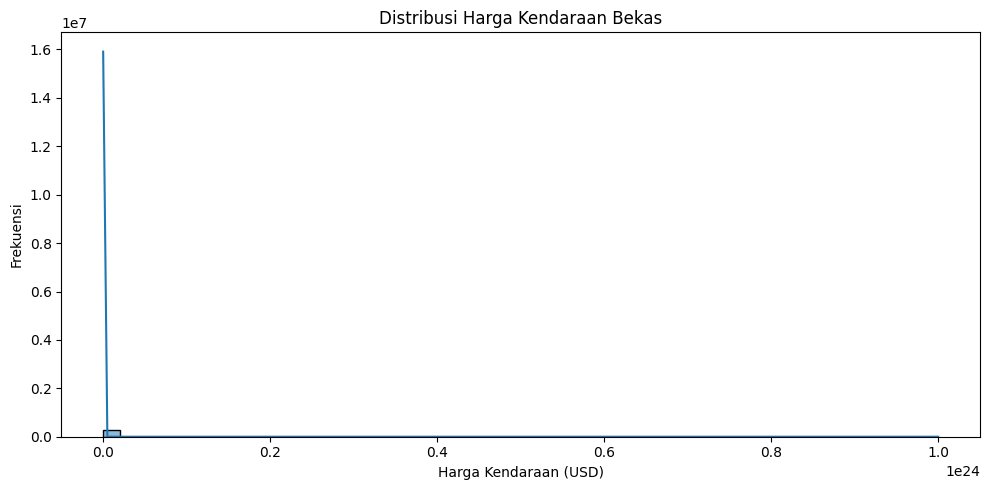

In [26]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_eda,
    x='price',
    bins=50,
    kde=True
)

plt.title('Distribusi Harga Kendaraan Bekas')
plt.xlabel('Harga Kendaraan (USD)')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()

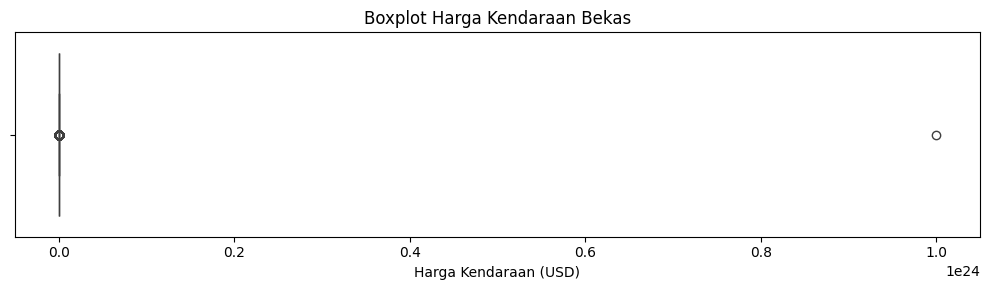

In [27]:
plt.figure(figsize=(10, 3))

sns.boxplot(x=df_eda['price'])

plt.title('Boxplot Harga Kendaraan Bekas')
plt.xlabel('Harga Kendaraan (USD)')
plt.tight_layout()
plt.show()

In [28]:
# Melihat 20 harga kendaraan tertinggi
display(
    df_eda.nlargest(20, 'price')[
        ['manufacturer', 'model', 'year', 'price']
    ]
)

,manufacturer,model,year,price
120108,mazda,protege,2001.0,1.000000e+24
50847,ford,f-150,1991.0,1.111111e+16
101596,gmc,NaN,1950.0,1.000000e+12
168494,chevrolet,NaN,2017.0,1.111111e+11
120040,NaN,any,2017.0,1.111111e+10
35260,chevrolet,NaN,1967.0,1.111111e+09
34758,ram,2500hd,2007.0,1.000000e+09
55472,chevrolet,silverado,2012.0,9.876543e+08
55474,chevrolet,silverado 2500,2016.0,9.876543e+08
291379,ram,3500,2002.0,9.876543e+08


In [29]:
# Menghitung harga nol
print("Harga nol:", (df_eda['price'] == 0).sum())

# Menghitung harga negatif
print("Harga negatif:", (df_eda['price'] < 0).sum())

# Menghitung harga positif
print("Harga positif:", (df_eda['price'] > 0).sum())

Harga nol: 10288
Harga negatif: 0
Harga positif: 285163


In [30]:
# Memeriksa persentil harga
print(
    df_eda['price'].quantile(
        [0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999]
    )
)

0.250      6200.0
0.500     12500.0
0.750     22500.0
0.900     36999.0
0.950     49993.0
0.990     89900.0
0.995    111111.0
0.999    234991.0
Name: price, dtype: float64


In [33]:
# Audit kualitas harga kendaraan

total_data = len(df_eda)

harga_nol = (df_eda['price'] == 0).sum()
harga_positif = (df_eda['price'] > 0).sum()
harga_diatas_100rb = (df_eda['price'] > 100000).sum()
harga_diatas_1juta = (df_eda['price'] > 1000000).sum()

print("Total data:", total_data)
print("Harga nol:", harga_nol)
print("Harga positif:", harga_positif)
print("Harga di atas $100.000:", harga_diatas_100rb)
print("Harga di atas $1.000.000:", harga_diatas_1juta)

print("\nPersentase harga nol:",
      round(harga_nol / total_data * 100, 2), "%")

print("Persentase harga di atas $100.000:",
      round(harga_diatas_100rb / total_data * 100, 2), "%")

Total data: 295451
Harga nol: 10288
Harga positif: 285163
Harga di atas $100.000: 1762
Harga di atas $1.000.000: 71

Persentase harga nol: 3.48 %
Persentase harga di atas $100.000: 0.6 %


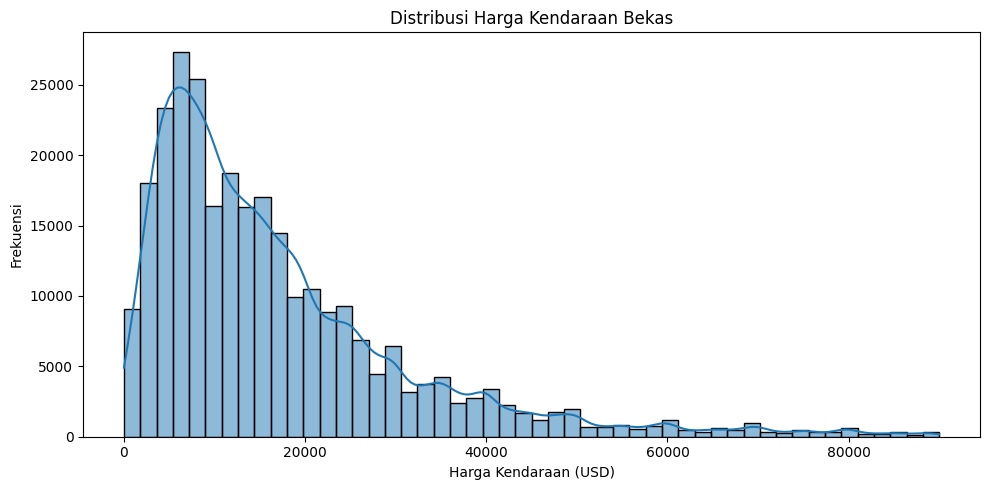

In [31]:
# Mengambil data harga positif
price_positive = df_eda.loc[
    df_eda['price'] > 0, 'price'
]

# Menghitung batas persentil ke-99
batas_99 = price_positive.quantile(0.99)

# Membatasi data khusus visualisasi
price_viz = price_positive[
    price_positive <= batas_99
]

# Membuat histogram
plt.figure(figsize=(10, 5))

sns.histplot(
    price_viz,
    bins=50,
    kde=True
)

plt.title('Distribusi Harga Kendaraan Bekas')
plt.xlabel('Harga Kendaraan (USD)')
plt.ylabel('Frekuensi')

plt.tight_layout()
plt.show()

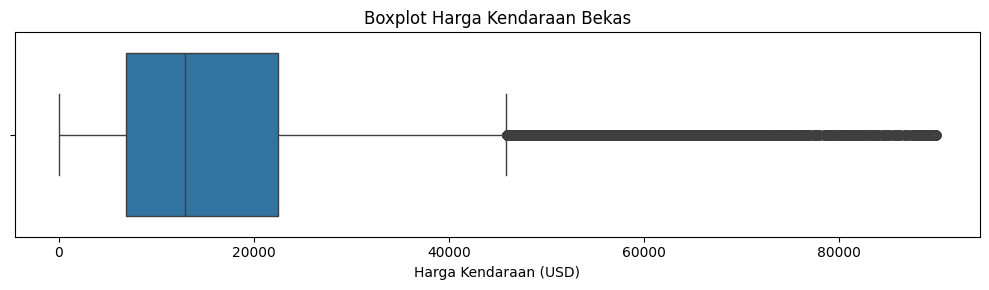

In [32]:
plt.figure(figsize=(10, 3))

sns.boxplot(x=price_viz)

plt.title('Boxplot Harga Kendaraan Bekas')
plt.xlabel('Harga Kendaraan (USD)')

plt.tight_layout()
plt.show()

### EDA Q1 – Analisis Distribusi Harga Kendaraan Bekas

Berdasarkan hasil eksplorasi terhadap 295.451 data kendaraan, ditemukan bahwa variabel harga memiliki nilai minimum sebesar USD 0 dan median sebesar USD 12.500. Namun, nilai rata-rata mencapai sekitar USD 3,38 × 10¹⁸ dengan nilai maksimum sebesar USD 10²⁴. Perbedaan yang sangat besar antara rata-rata dan median menunjukkan adanya nilai ekstrem yang memengaruhi distribusi harga.

Pemeriksaan lebih lanjut menemukan 10.288 data dengan harga nol dan tidak ditemukan harga negatif. Selain itu, terdapat sejumlah nilai harga yang mencurigakan, seperti USD 123.456.789 dan USD 999.999.996, yang mengindikasikan kemungkinan kesalahan input atau penggunaan nilai placeholder.

Berdasarkan analisis persentil, sebanyak 99% data harga berada pada atau di bawah USD 89.900. Oleh karena itu, diperlukan pemeriksaan dan penanganan nilai ekstrem pada tahap Data Processing agar analisis distribusi harga dapat memberikan gambaran yang lebih representatif.

### Kesimpulan EDA Q1 – Distribusi Harga Kendaraan Bekas

Berdasarkan analisis terhadap 295.451 data kendaraan, diketahui bahwa harga kendaraan memiliki median sebesar USD 12.500 dan kuartil pertama serta ketiga masing-masing sebesar USD 6.200 dan USD 22.500. Hasil visualisasi histogram menunjukkan bahwa distribusi harga cenderung menceng ke kanan (*right-skewed*), yang berarti sebagian besar kendaraan berada pada rentang harga rendah hingga menengah, sementara sebagian kecil kendaraan memiliki harga jauh lebih tinggi.

Hasil audit menemukan 10.288 data dengan harga nol atau sekitar 3,48% dari keseluruhan dataset. Selain itu, terdapat 1.762 data dengan harga di atas USD 100.000 dan 71 data di atas USD 1.000.000. Temuan ini menunjukkan adanya sejumlah nilai ekstrem yang perlu diperiksa lebih lanjut.

Dengan demikian, diperlukan proses pembersihan dan validasi data harga agar analisis selanjutnya dapat memberikan gambaran distribusi harga kendaraan yang lebih Baik.

#Step 5 — Exploratory Data Analysis (EDA), Q2.

In [34]:
# Q2: Hubungan Tahun Produksi dan Odometer terhadap Harga

# Memilih variabel yang diperlukan
q2_data = df_eda[['year', 'odometer', 'price']].copy()

# Melihat statistik deskriptif
q2_data.describe()

,year,odometer,price
count,295425.000000,2.914150e+05,2.954510e+05
mean,2012.771235,1.145619e+05,3.384656e+18
std,11.580429,1.713099e+05,1.839743e+21
min,1900.000000,1.000000e+00,0.000000e+00
25%,2010.000000,6.762650e+04,6.200000e+03
50%,2015.000000,1.075000e+05,1.250000e+04
75%,2019.000000,1.473720e+05,2.250000e+04
max,2027.000000,1.000000e+07,1.000000e+24


In [35]:
# Membuat salinan khusus visualisasi Q2
q2_viz = q2_data.copy()

# Menghitung batas persentil ke-99
batas_price = q2_viz['price'].quantile(0.99)
batas_odo = q2_viz['odometer'].quantile(0.99)

# Memilih data untuk visualisasi
q2_viz = q2_viz[
    (q2_viz['price'] > 0) &
    (q2_viz['price'] <= batas_price) &
    (q2_viz['odometer'] > 0) &
    (q2_viz['odometer'] <= batas_odo) &
    (q2_viz['year'] <= 2026)
].dropna()

print("Jumlah data awal:", len(q2_data))
print("Jumlah data visualisasi:", len(q2_viz))
print("Batas harga:", batas_price)
print("Batas odometer:", batas_odo)

Jumlah data awal: 295451
Jumlah data visualisasi: 275476
Batas harga: 89900.0
Batas odometer: 295697.61999999976


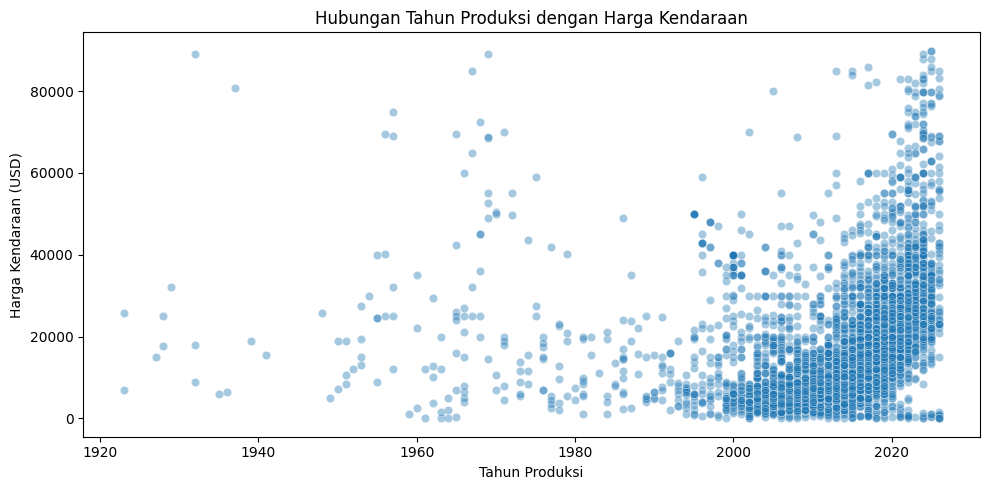

In [36]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=q2_viz.sample(
        n=min(5000, len(q2_viz)),
        random_state=42
    ),
    x='year',
    y='price',
    alpha=0.4
)

plt.title('Hubungan Tahun Produksi dengan Harga Kendaraan')
plt.xlabel('Tahun Produksi')
plt.ylabel('Harga Kendaraan (USD)')

plt.tight_layout()
plt.show()

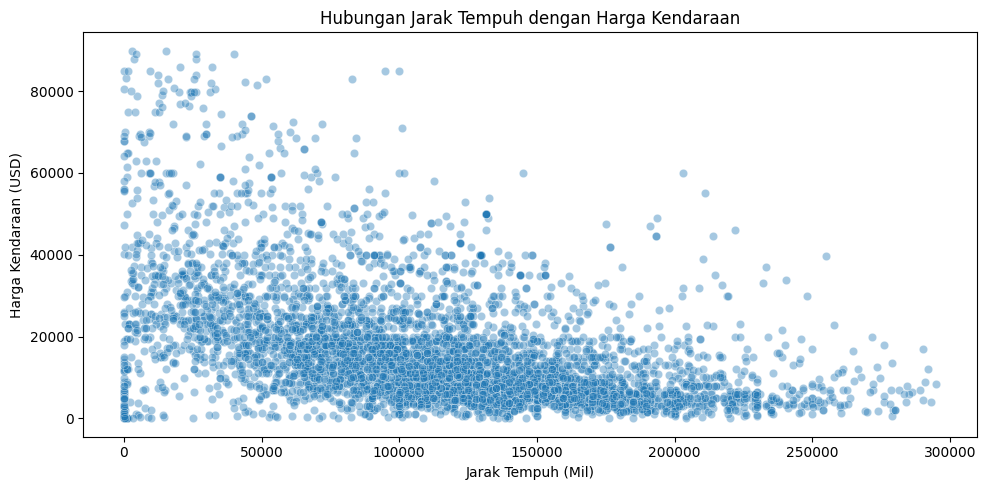

In [37]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=q2_viz.sample(
        n=min(5000, len(q2_viz)),
        random_state=42
    ),
    x='odometer',
    y='price',
    alpha=0.4
)

plt.title('Hubungan Jarak Tempuh dengan Harga Kendaraan')
plt.xlabel('Jarak Tempuh (Mil)')
plt.ylabel('Harga Kendaraan (USD)')

plt.tight_layout()
plt.show()

### EDA Q2 – Hubungan Tahun Produksi dan Jarak Tempuh terhadap Harga Kendaraan

Analisis Q2 dilakukan untuk mengetahui hubungan antara tahun produksi dan jarak tempuh kendaraan terhadap harga jual kendaraan bekas. Visualisasi menggunakan scatter plot dengan pembatasan persentil ke-99 pada harga dan odometer untuk memperjelas pola persebaran data.

Berdasarkan scatter plot pertama, terlihat kecenderungan hubungan positif antara tahun produksi dan harga kendaraan. Kendaraan dengan tahun produksi lebih baru cenderung memiliki harga lebih tinggi dibandingkan kendaraan yang lebih tua. Meskipun demikian, terdapat variasi harga pada setiap tahun produksi, yang menunjukkan bahwa harga tidak hanya dipengaruhi oleh tahun kendaraan.

Pada scatter plot kedua, terlihat kecenderungan hubungan negatif antara jarak tempuh dan harga kendaraan. Kendaraan dengan jarak tempuh rendah memiliki variasi harga yang lebih luas, sedangkan kendaraan dengan jarak tempuh tinggi cenderung memiliki harga lebih rendah.

Hasil tersebut menunjukkan bahwa tahun produksi dan jarak tempuh merupakan dua karakteristik yang memiliki pola hubungan dengan harga kendaraan. Namun, pola visualisasi ini belum menunjukkan kekuatan hubungan secara statistik sehingga diperlukan analisis korelasi lebih lanjut.

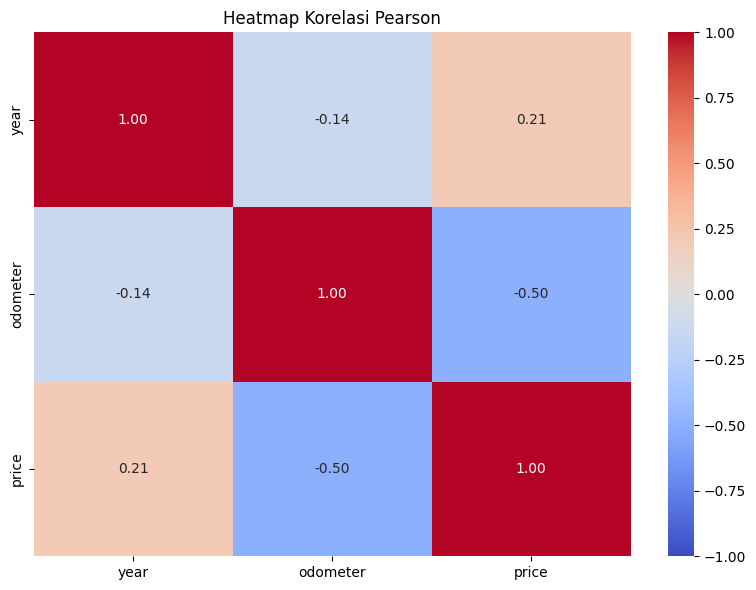

In [40]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Heatmap Korelasi Pearson')
plt.tight_layout()
plt.show()

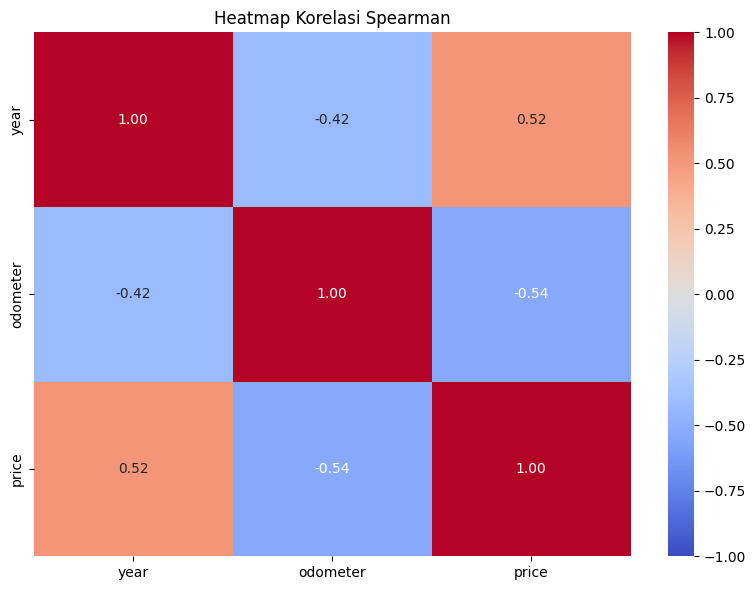

In [41]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    spearman_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Heatmap Korelasi Spearman')
plt.tight_layout()
plt.show()

### Kesimpulan EDA Q2 – Hubungan Tahun Produksi dan Jarak Tempuh terhadap Harga Kendaraan

Berdasarkan hasil analisis scatter plot dan heatmap korelasi, ditemukan bahwa tahun produksi dan jarak tempuh memiliki hubungan dengan harga kendaraan bekas.

Hasil korelasi Pearson menunjukkan hubungan positif lemah antara tahun produksi dan harga dengan nilai 0,209. Sementara itu, hubungan jarak tempuh dan harga menunjukkan korelasi negatif sedang sebesar -0,496.

Pada analisis Spearman, hubungan tahun produksi dan harga memiliki nilai korelasi positif sedang sebesar 0,523, sedangkan hubungan jarak tempuh dan harga memiliki nilai korelasi negatif sedang sebesar -0,538.

Perbedaan hasil Pearson dan Spearman menunjukkan bahwa hubungan antarvariabel tidak sepenuhnya linear. Secara umum, kendaraan dengan tahun produksi lebih baru cenderung memiliki harga lebih tinggi, sedangkan kendaraan dengan jarak tempuh lebih tinggi cenderung memiliki harga lebih rendah.

Hasil ini menunjukkan bahwa tahun produksi dan jarak tempuh merupakan karakteristik yang relevan dalam analisis harga kendaraan. Namun, korelasi tidak menunjukkan hubungan sebab-akibat dan harga juga dapat dipengaruhi oleh faktor lain.

#Step 5 (Lanjutan) — Exploratory Data Analysis (EDA), Q3


In [42]:
# Q3: Analisis Karakteristik Kendaraan

# Distribusi merek kendaraan
print("10 Merek Kendaraan Terbanyak:")
display(df['manufacturer'].value_counts().head(10))

# Distribusi jenis bahan bakar
print("\nJenis Bahan Bakar:")
display(df['fuel'].value_counts())

# Distribusi transmisi
print("\nJenis Transmisi:")
display(df['transmission'].value_counts())

10 Merek Kendaraan Terbanyak:


,count
manufacturer,
ford,51374
chevrolet,34006
toyota,27042
honda,17404
nissan,14375
ram,14297
jeep,13510
subaru,10840
gmc,10678



Jenis Bahan Bakar:


,count
fuel,
gas,249863
diesel,25093
other,7642
hybrid,7454
electric,4268



Jenis Transmisi:


,count
transmission,
automatic,266946
manual,19067
other,7882


In [43]:
# Membuat salinan data untuk Q3
q3_data = df_eda[
    ['manufacturer', 'fuel', 'transmission', 'price']
].copy()

# Mengambil harga positif
q3_data = q3_data[q3_data['price'] > 0]

# Membatasi harga sampai persentil ke-99
batas_q3 = q3_data['price'].quantile(0.99)

q3_viz = q3_data[
    q3_data['price'] <= batas_q3
].copy()

print("Jumlah data awal:", len(df_eda))
print("Jumlah data untuk Q3:", len(q3_viz))
print("Batas harga:", batas_q3)

Jumlah data awal: 295451
Jumlah data untuk Q3: 282312
Batas harga: 89995.0


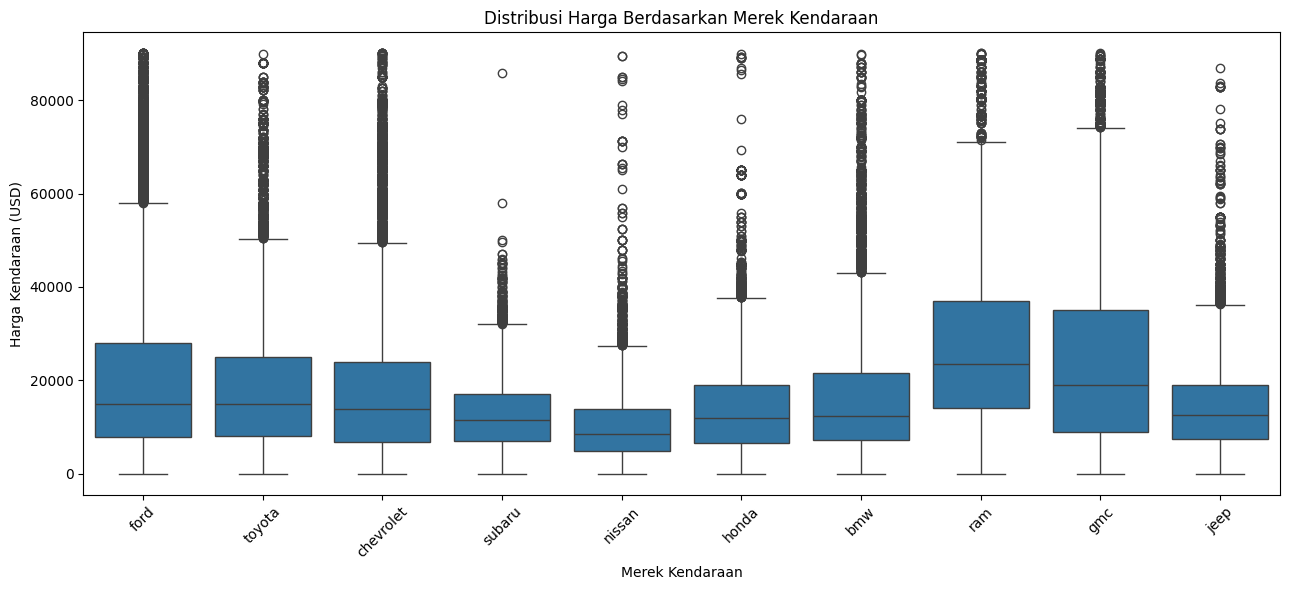

In [44]:
# Mengambil 10 merek dengan listing terbanyak
top_manufacturers = (
    q3_viz['manufacturer']
    .value_counts()
    .head(10)
    .index
)

manufacturer_data = q3_viz[
    q3_viz['manufacturer'].isin(top_manufacturers)
]

plt.figure(figsize=(13, 6))

sns.boxplot(
    data=manufacturer_data,
    x='manufacturer',
    y='price'
)

plt.title('Distribusi Harga Berdasarkan Merek Kendaraan')
plt.xlabel('Merek Kendaraan')
plt.ylabel('Harga Kendaraan (USD)')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

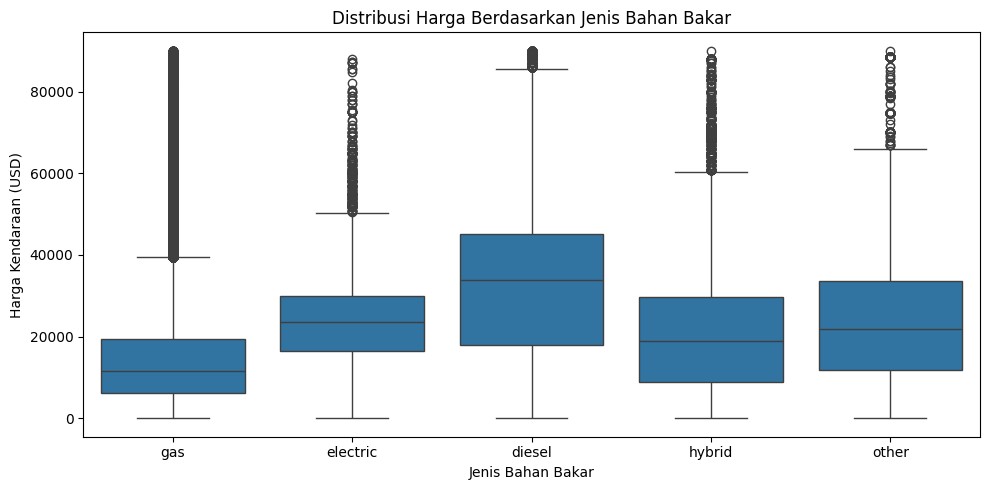

In [45]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=q3_viz,
    x='fuel',
    y='price'
)

plt.title('Distribusi Harga Berdasarkan Jenis Bahan Bakar')
plt.xlabel('Jenis Bahan Bakar')
plt.ylabel('Harga Kendaraan (USD)')

plt.tight_layout()
plt.show()

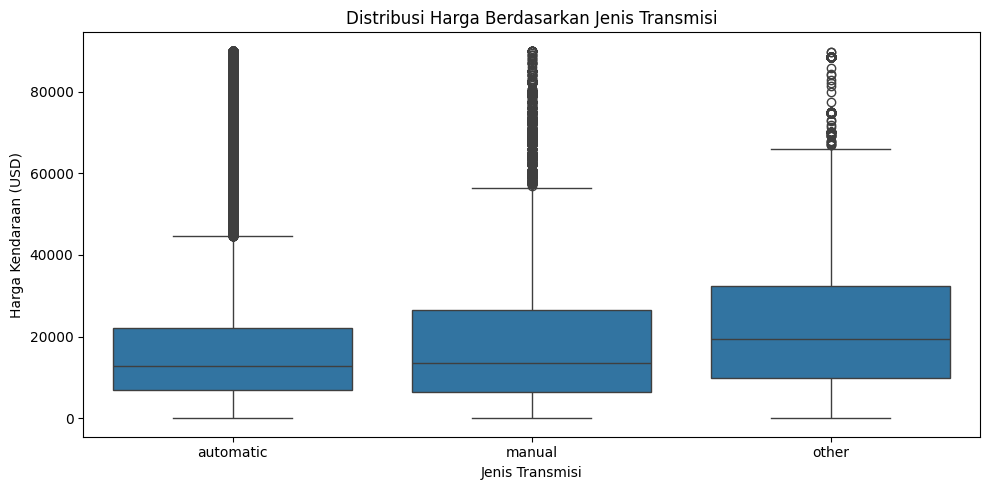

In [46]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=q3_viz,
    x='transmission',
    y='price'
)

plt.title('Distribusi Harga Berdasarkan Jenis Transmisi')
plt.xlabel('Jenis Transmisi')
plt.ylabel('Harga Kendaraan (USD)')

plt.tight_layout()
plt.show()

In [47]:
manufacturer_price = (
    manufacturer_data
    .groupby('manufacturer')['price']
    .agg(['count', 'median', 'mean'])
    .sort_values('median', ascending=False)
)

display(manufacturer_price)

,count,median,mean
manufacturer,,,
ram,13818,23496.5,26617.533652
gmc,10162,18986.5,25407.668864
ford,48781,15000.0,20414.255325
toyota,26096,14995.0,17967.911289
chevrolet,32457,13951.0,17779.144622
jeep,13029,12626.0,14352.352214
bmw,9144,12397.5,17120.458990
honda,16754,11995.0,13725.770144
subaru,10553,11490.0,12782.324552


In [48]:
fuel_price = (
    q3_viz
    .groupby('fuel')['price']
    .agg(['count', 'median', 'mean'])
    .sort_values('median', ascending=False)
)

display(fuel_price)

,count,median,mean
fuel,,,
diesel,23531,33970.0,34600.610046
electric,4028,23499.5,25008.703327
other,7314,21985.0,24670.235165
hybrid,6805,18900.0,22783.947245
gas,239629,11500.0,14874.614763


In [49]:
transmission_price = (
    q3_viz
    .groupby('transmission')['price']
    .agg(['count', 'median', 'mean'])
    .sort_values('median', ascending=False)
)

display(transmission_price)

,count,median,mean
transmission,,,
other,7364,19500.0,23544.011814
manual,18429,13500.0,19332.130555
automatic,255055,12800.0,16775.556829


### EDA Q3 – Analisis Karakteristik Harga Berdasarkan Merek, Bahan Bakar, dan Transmisi

Analisis Q3 dilakukan untuk mengetahui perbedaan karakteristik harga kendaraan berdasarkan merek kendaraan, jenis bahan bakar, dan jenis transmisi.

Berdasarkan hasil analisis harga berdasarkan merek kendaraan, RAM memiliki median harga tertinggi sebesar USD 23.496,50, diikuti oleh GMC sebesar USD 18.986,50. Sementara itu, Nissan memiliki median harga terendah sebesar USD 8.450. Hasil ini menunjukkan bahwa terdapat variasi harga yang cukup besar di antara merek kendaraan yang dianalisis.

Pada analisis berdasarkan jenis bahan bakar, kendaraan diesel memiliki median harga tertinggi sebesar USD 33.970, diikuti kendaraan electric sebesar USD 23.499,50. Sementara itu, kendaraan berbahan bakar gas memiliki median harga sebesar USD 11.500. Meskipun gas merupakan jenis bahan bakar yang paling banyak ditemukan dalam dataset, median harganya merupakan yang terendah dibandingkan kategori bahan bakar lainnya.

Selanjutnya, berdasarkan jenis transmisi, kategori other memiliki median harga sebesar USD 19.500, manual sebesar USD 13.500, dan automatic sebesar USD 12.800. Hasil tersebut menunjukkan adanya perbedaan distribusi harga berdasarkan jenis transmisi.

Secara keseluruhan, hasil EDA Q3 menunjukkan bahwa harga kendaraan memiliki variasi berdasarkan merek, jenis bahan bakar, dan transmisi. Namun, perbedaan harga tersebut tidak dapat dikaitkan secara langsung hanya dengan satu karakteristik karena masih terdapat faktor lain seperti tahun produksi, jarak tempuh, kondisi, dan model kendaraan.

#Step 6 — Data Processing dan Cleaning


In [50]:
# Membuat salinan dataset untuk proses Data Processing
df_clean = df.copy()

# Memastikan dataset asli tidak berubah
print("Jumlah data asli:", df.shape)
print("Jumlah data salinan:", df_clean.shape)

print("\nDataset berhasil disalin!")

Jumlah data asli: (295451, 41)
Jumlah data salinan: (295451, 41)

Dataset berhasil disalin!


In [51]:
# Menghitung missing values
missing_audit = pd.DataFrame({
    'Missing Values': df_clean.isnull().sum(),
    'Percentage (%)': (
        df_clean.isnull().sum() / len(df_clean) * 100
    )
})

# Mengurutkan dari missing terbanyak
missing_audit = missing_audit.sort_values(
    by='Percentage (%)',
    ascending=False
)

display(missing_audit)

,Missing Values,Percentage (%)
size,295451,100.000000
county,295451,100.000000
other_attributes,291688,98.726354
monthly_payment,289398,97.951268
updated_date,179711,60.825991
address_street,138758,46.964810
condition,135490,45.858704
VIN,121119,40.994615
cylinders,80167,27.133772
paint_color,74718,25.289473


In [52]:
# Memeriksa duplikasi seluruh baris
duplicate_rows = df_clean.duplicated().sum()

# Memeriksa duplikasi berdasarkan ID
duplicate_id = df_clean['id'].duplicated().sum()

print("Duplikasi seluruh baris:", duplicate_rows)
print("Duplikasi ID:", duplicate_id)

Duplikasi seluruh baris: 0
Duplikasi ID: 0


In [53]:
# Melihat tipe data setiap kolom
dtype_audit = pd.DataFrame({
    'Column': df_clean.columns,
    'Data Type': df_clean.dtypes.values,
    'Unique Values': [
        df_clean[col].nunique()
        for col in df_clean.columns
    ]
})

display(dtype_audit)

,Column,Data Type,Unique Values
0,id,int64,295451
1,url,object,295451
2,region,object,400
3,region_url,object,412
4,price,object,15574
5,year,float64,114
6,manufacturer,object,42
7,model,object,27958
8,condition,object,6
9,cylinders,object,8


In [54]:
# Mengonversi sementara untuk pemeriksaan
price_check = pd.to_numeric(
    df_clean['price'], errors='coerce'
)

year_check = pd.to_numeric(
    df_clean['year'], errors='coerce'
)

odometer_check = pd.to_numeric(
    df_clean['odometer'], errors='coerce'
)

# Membuat ringkasan audit
print("=== AUDIT PRICE ===")
print("Harga nol:", (price_check == 0).sum())
print("Harga negatif:", (price_check < 0).sum())
print("Harga di atas 100.000:",
      (price_check > 100000).sum())
print("Harga di atas 1 juta:",
      (price_check > 1000000).sum())

print("\n=== AUDIT YEAR ===")
print("Tahun sebelum 1900:",
      (year_check < 1900).sum())
print("Tahun setelah 2026:",
      (year_check > 2026).sum())

print("\n=== AUDIT ODOMETER ===")
print("Odometer nol:",
      (odometer_check == 0).sum())
print("Odometer negatif:",
      (odometer_check < 0).sum())
print("Odometer di atas 1 juta:",
      (odometer_check > 1000000).sum())

=== AUDIT PRICE ===
Harga nol: 10288
Harga negatif: 0
Harga di atas 100.000: 1762
Harga di atas 1 juta: 71

=== AUDIT YEAR ===
Tahun sebelum 1900: 0
Tahun setelah 2026: 535

=== AUDIT ODOMETER ===
Odometer nol: 0
Odometer negatif: 0
Odometer di atas 1 juta: 287


In [55]:
# Menghapus kolom dengan 100% missing values
kolom_dihapus = ['size', 'county']

df_clean = df_clean.drop(columns=kolom_dihapus)

print("Kolom yang dihapus:", kolom_dihapus)
print("Ukuran dataset setelah cleaning:", df_clean.shape)

Kolom yang dihapus: ['size', 'county']
Ukuran dataset setelah cleaning: (295451, 39)


In [56]:
# Memeriksa other_attributes
print("=== OTHER ATTRIBUTES ===")
display(df_clean['other_attributes'].value_counts().head(10))

# Memeriksa monthly_payment
print("\n=== MONTHLY PAYMENT ===")
display(df_clean['monthly_payment'].dropna().head(10))

print(
    "\nJumlah data monthly_payment:",
    df_clean['monthly_payment'].notna().sum()
)

=== OTHER ATTRIBUTES ===


,count
other_attributes,
cryptocurrency ok,3763



=== MONTHLY PAYMENT ===


,monthly_payment
1071,$187
1088,$300
1107,$250
1116,$350
1119,$250
1381,$369
1447,$350
1451,$340
1731,$250
1737,$350



Jumlah data monthly_payment: 6053


In [57]:
df_clean['price'] = pd.to_numeric(
    df_clean['price'],
    errors='coerce'
)

print("Tipe data price:", df_clean['price'].dtype)
print("Missing price:", df_clean['price'].isna().sum())

display(df_clean['price'].describe())

Tipe data price: float64
Missing price: 0


,price
count,2.954510e+05
mean,3.384656e+18
std,1.839743e+21
min,0.000000e+00
25%,6.200000e+03
50%,1.250000e+04
75%,2.250000e+04
max,1.000000e+24


In [58]:
df_clean['posting_date'] = pd.to_datetime(
    df_clean['posting_date'],
    errors='coerce',
    utc=True
)

df_clean['updated_date'] = pd.to_datetime(
    df_clean['updated_date'],
    errors='coerce',
    utc=True
)

print(df_clean[
    ['posting_date', 'updated_date']
].dtypes)

posting_date    datetime64[ns, UTC]
updated_date    datetime64[ns, UTC]
dtype: object


In [61]:
# Kolom yang tidak digunakan
kolom_dihapus = [
    'size',
    'county',
    'other_attributes',
    'monthly_payment'
]

# Hanya menghapus kolom yang masih tersedia
kolom_tersedia = [
    kolom for kolom in kolom_dihapus
    if kolom in df_clean.columns
]

df_clean = df_clean.drop(columns=kolom_tersedia)

print("Kolom berhasil dihapus:", kolom_tersedia)
print("Ukuran dataset sekarang:", df_clean.shape)

Kolom berhasil dihapus: ['other_attributes', 'monthly_payment']
Ukuran dataset sekarang: (295451, 37)


In [62]:
# Menampilkan 20 data dengan harga tertinggi
harga_tertinggi = df_clean.nlargest(20, 'price')[
    ['id', 'manufacturer', 'model', 'year', 'price']
]

display(harga_tertinggi)

,id,manufacturer,model,year,price
120108,7986143880,mazda,protege,2001.0,1.000000e+24
50847,7985869728,ford,f-150,1991.0,1.111111e+16
101596,7988034108,gmc,NaN,1950.0,1.000000e+12
168494,7992862152,chevrolet,NaN,2017.0,1.111111e+11
120040,7987497975,NaN,any,2017.0,1.111111e+10
35260,7987383873,chevrolet,NaN,1967.0,1.111111e+09
34758,7982506554,ram,2500hd,2007.0,1.000000e+09
55472,7993625277,chevrolet,silverado,2012.0,9.876543e+08
55474,7993614918,chevrolet,silverado 2500,2016.0,9.876543e+08
291379,7993593276,ram,3500,2002.0,9.876543e+08


In [63]:
# Menampilkan 15 data kendaraan dengan harga 0
harga_nol = df_clean[df_clean['price'] == 0][
    ['manufacturer', 'model', 'year', 'price', 'condition']
]

display(harga_nol.head(15))

print("Jumlah kendaraan dengan harga 0:",
      (df_clean['price'] == 0).sum())

,manufacturer,model,year,price,condition
49,ford,f-150 xlt,2026.0,0.0,excellent
83,ford,bronco sport big bend,2026.0,0.0,excellent
101,mercedes-benz,gle350,2023.0,0.0,like new
105,mercedes-benz,gle350,2023.0,0.0,like new
327,honda,accord lx sedan 4d,2011.0,0.0,NaN
332,lexus,nx,2020.0,0.0,excellent
333,mazda,cx 30,2025.0,0.0,excellent
338,mini,hardtop 4 door cooper hatc,2015.0,0.0,NaN
370,lexus,rc,2016.0,0.0,excellent
371,lexus,gs,2015.0,0.0,excellent


Jumlah kendaraan dengan harga 0: 10288


In [64]:
# Memeriksa kendaraan dengan harga di atas 1 juta
harga_ekstrem = df_clean[df_clean['price'] > 1_000_000][
    ['id', 'manufacturer', 'model', 'year',
     'price', 'condition', 'title', 'description']
]

print("Jumlah harga di atas 1 juta:",
      len(harga_ekstrem))

display(harga_ekstrem.head(20))

Jumlah harga di atas 1 juta: 71


,id,manufacturer,model,year,price,condition,title,description
8604,7986017154,toyota,tacoma,2002.0,9.999999e+06,good,Wanted~ cash for cars~ any condition pay up to...,Wanted~ cash for cars~ any condition We pay t...
8608,7986005556,toyota,tacoma,2002.0,9.999999e+06,good,Wanted~ cash for cars~ any condition pay up to...,Wanted~ cash for cars~ any condition We pay t...
14102,7979517222,mazda,NaN,1972.0,1.000000e+08,NaN,"Wanted. Mazda rx2,rx3,rx4 rx7,pick up,REPU Cosmo","I'm looking for a Mazda rx2 rx3 rx7 Cosmo,rx4,..."
14466,7978888305,toyota,tacoma,2002.0,9.999999e+06,good,Wanted~ cash for cars~ any condition pay up to...,Wanted~ cash for cars~ any condition We pay t...
14467,7978887936,toyota,tacoma,2002.0,9.999999e+06,good,Wanted~ cash for cars~ any condition pay up to...,Wanted~ cash for cars~ any condition We pay t...
14468,7978886598,toyota,tacoma,2002.0,9.999999e+06,good,Wanted~ cash for cars~ any condition pay up to...,Wanted~ cash for cars~ any condition We pay t...
18758,7980020238,gmc,c4500,2003.0,1.234568e+08,NaN,2003 GMC 4500 Dumptruck,"GMC 2003 c4500 dumptruck with 57,617 miles. P..."
34758,7982506554,ram,2500hd,2007.0,1.000000e+09,NaN,2007 Dodge ram 2500hd 5.9,I have a 2007 Dodge ram 2500hd with the sought...
35260,7987383873,chevrolet,NaN,1967.0,1.111111e+09,NaN,1967 Chevelle SS 138,I have a 1967 Chevelle ss138 Vin came factory ...
50847,7985869728,ford,f-150,1991.0,1.111111e+16,excellent,1991 Ford F-150,Engine 300 Call Greg show contact info


In [65]:
# Distribusi jumlah kendaraan berdasarkan rentang harga
rentang_harga = {
    'Harga 0': (df_clean['price'] == 0).sum(),
    'Harga 1 - 100.000': (
        (df_clean['price'] > 0) &
        (df_clean['price'] <= 100_000)
    ).sum(),
    'Harga 100.001 - 1.000.000': (
        (df_clean['price'] > 100_000) &
        (df_clean['price'] <= 1_000_000)
    ).sum(),
    'Harga di atas 1.000.000': (
        df_clean['price'] > 1_000_000
    ).sum()
}

for kategori, jumlah in rentang_harga.items():
    print(f"{kategori}: {jumlah:,}")

Harga 0: 10,288
Harga 1 - 100.000: 283,401
Harga 100.001 - 1.000.000: 1,691
Harga di atas 1.000.000: 71


In [66]:
import numpy as np

# Menghitung jumlah data sebelum dibersihkan
jumlah_harga_nol = (df_clean['price'] == 0).sum()
jumlah_harga_ekstrem = (df_clean['price'] > 1_000_000).sum()

# Mengubah harga 0 menjadi NaN
df_clean.loc[df_clean['price'] == 0, 'price'] = np.nan

# Mengubah harga di atas 1 juta menjadi NaN
df_clean.loc[df_clean['price'] > 1_000_000, 'price'] = np.nan

print("Harga 0 yang diubah menjadi NaN:", jumlah_harga_nol)
print("Harga di atas 1 juta yang diubah menjadi NaN:", jumlah_harga_ekstrem)
print("Total harga yang ditangani:", jumlah_harga_nol + jumlah_harga_ekstrem)
print("Jumlah missing value pada price:", df_clean['price'].isna().sum())
print("Ukuran dataset:", df_clean.shape)

Harga 0 yang diubah menjadi NaN: 10288
Harga di atas 1 juta yang diubah menjadi NaN: 71
Total harga yang ditangani: 10359
Jumlah missing value pada price: 10359
Ukuran dataset: (295451, 37)


In [67]:
# Statistik harga setelah penanganan anomali
display(df_clean['price'].describe())

print("Harga minimum:", df_clean['price'].min())
print("Harga maksimum:", df_clean['price'].max())
print("Jumlah missing value:", df_clean['price'].isna().sum())

,price
count,285092.000000
mean,18313.384813
std,20541.063017
min,1.000000
25%,6950.000000
50%,12995.000000
75%,22995.000000
max,1000000.000000


Harga minimum: 1.0
Harga maksimum: 1000000.0
Jumlah missing value: 10359


NOTES

Interpretasi: Rata-rata harga sekarang jauh lebih representatif dibandingkan sebelumnya. Sebelumnya rata-rata mencapai sekitar \(3,38 \times 10^{18}\), akibat nilai harga yang tidak wajar. Setelah penanganan, rata-rata menjadi sekitar $18.313.

Harga maksimum masih $1.000.000 karena batas yang kita gunakan adalah lebih dari 1 juta, bukan sama dengan 1 juta. Nilai tersebut belum otomatis salah, sehingga kita pertahankan sementara.

In [68]:
# Statistik tahun kendaraan
display(df_clean['year'].describe())

# Jumlah kendaraan berdasarkan tahun di atas 2026
tahun_ekstrem = df_clean[df_clean['year'] > 2026][
    ['id', 'manufacturer', 'model', 'year', 'price']
]

print("Jumlah kendaraan dengan tahun > 2026:",
      len(tahun_ekstrem))

display(tahun_ekstrem.head(20))

,year
count,295425.000000
mean,2012.771235
std,11.580429
min,1900.000000
25%,2010.000000
50%,2015.000000
75%,2019.000000
max,2027.000000


Jumlah kendaraan dengan tahun > 2026: 535


,id,manufacturer,model,year,price
456,7994062467,ford,expedition max platinum,2027.0,1658.0
577,7993953717,toyota,corolla le,2027.0,NaN
583,7993945200,toyota,corolla le,2027.0,NaN
606,7993902927,toyota,camry se,2027.0,NaN
857,7993586232,ford,super duty f-350 srw xl,2027.0,1092.0
895,7993551045,ford,super duty f-350 srw xl,2027.0,1091.0
934,7993503075,toyota,camry hybrid le,2027.0,29999.0
2384,7992470115,ford,super duty f-250 srw xl,2027.0,974.0
2848,7992150297,ford,super duty f-350 lariat,2027.0,1816.0
2938,7992086520,ford,transit van,2027.0,1193.0


In [69]:
# Menampilkan 15 tahun kendaraan dengan jumlah terbanyak
display(
    df_clean['year']
    .value_counts()
    .sort_values(ascending=False)
    .head(15)
)

,count
year,
2017.0,19267
2015.0,19220
2016.0,18766
2018.0,18122
2019.0,17717
2014.0,16636
2013.0,14915
2020.0,13491
2012.0,12172


In [70]:
# Memeriksa kendaraan tahun 1900
display(
    df_clean[df_clean['year'] == 1900][
        ['manufacturer', 'model', 'year', 'price',
         'condition', 'description']
    ]
)

,manufacturer,model,year,price,condition,description
8755,harley-davidson,NaN,1900.0,NaN,excellent,Cleaning out the toy box. Getting rid of every...
48795,NaN,ALL U.S. MADE VEHICLES,1900.0,1.0,NaN,Machine shop services specializing in engine a...
54648,toyota,corolla,1900.0,1500.0,NaN,2007 Mercedes slk 280 120k miles Automatic Con...
103936,NaN,homemade,1900.0,995.0,NaN,"Steel construction, no motor. Mid-engine style..."
108323,NaN,ALL,1900.0,1250.0,NaN,REPO CLEARANCE SALE !!! CASH CAR CLEARANCE SAL...
109443,NaN,ALL,1900.0,950.0,NaN,REPO CLEARANCE SALE !!! CASH CAR CLEARANCE SAL...
110201,NaN,ALL,1900.0,1250.0,NaN,REPO CLEARANCE SALE !!! CASH CAR CLEARANCE SAL...
112478,ford,fusion,1900.0,1.0,NaN,None of the cars are perfect recommend a inspe...
117453,nissan,leaf,1900.0,8.0,NaN,unavailable
222380,NaN,anything,1900.0,NaN,salvage,"Cars trucks, SUVs RVs, camping trailers Got so..."


In [71]:
# Ringkasan kendaraan tahun 2027
display(
    df_clean[df_clean['year'] == 2027][
        ['manufacturer', 'model', 'year', 'price']
    ].head(30)
)

print("Jumlah tahun 2027:",
      (df_clean['year'] == 2027).sum())

,manufacturer,model,year,price
456,ford,expedition max platinum,2027.0,1658.0
577,toyota,corolla le,2027.0,NaN
583,toyota,corolla le,2027.0,NaN
606,toyota,camry se,2027.0,NaN
857,ford,super duty f-350 srw xl,2027.0,1092.0
895,ford,super duty f-350 srw xl,2027.0,1091.0
934,toyota,camry hybrid le,2027.0,29999.0
2384,ford,super duty f-250 srw xl,2027.0,974.0
2848,ford,super duty f-350 lariat,2027.0,1816.0
2938,ford,transit van,2027.0,1193.0


Jumlah tahun 2027: 535


In [72]:
# Mengubah tahun 1900 menjadi missing value
jumlah_tahun_1900 = (df_clean['year'] == 1900).sum()

df_clean.loc[df_clean['year'] == 1900, 'year'] = np.nan

print("Tahun 1900 yang diubah menjadi NaN:", jumlah_tahun_1900)
print("Total missing value year:", df_clean['year'].isna().sum())
print("Jumlah baris dataset:", len(df_clean))

Tahun 1900 yang diubah menjadi NaN: 14
Total missing value year: 40
Jumlah baris dataset: 295451


In [73]:
# Statistik jarak tempuh kendaraan
display(df_clean['odometer'].describe())

print("Missing value:", df_clean['odometer'].isna().sum())
print("Odometer = 0:", (df_clean['odometer'] == 0).sum())
print("Odometer negatif:", (df_clean['odometer'] < 0).sum())
print("Odometer > 1 juta:", (df_clean['odometer'] > 1_000_000).sum())

,odometer
count,2.914150e+05
mean,1.145619e+05
std,1.713099e+05
min,1.000000e+00
25%,6.762650e+04
50%,1.075000e+05
75%,1.473720e+05
max,1.000000e+07


Missing value: 4036
Odometer = 0: 0
Odometer negatif: 0
Odometer > 1 juta: 287


In [74]:
odometer_tertinggi = df_clean.nlargest(20, 'odometer')[
    ['id', 'manufacturer', 'model', 'year',
     'odometer', 'odometer_broken', 'odometer_rolled_over']
]

display(odometer_tertinggi)

,id,manufacturer,model,year,odometer,odometer_broken,odometer_rolled_over
15047,7978127991,volkswagen,bus,1968.0,10000000.0,1,0
22070,7975453728,ford,f-250,1984.0,10000000.0,0,1
49243,7983397386,gmc,sierra 1500,1996.0,10000000.0,0,0
76480,7977672372,NaN,Corvette,1979.0,10000000.0,1,1
103043,7993502415,NaN,all,2025.0,10000000.0,0,0
103504,7991260347,NaN,all,2025.0,10000000.0,0,0
103658,7990125906,NaN,all,2025.0,10000000.0,0,0
103738,7989588027,NaN,all,2025.0,10000000.0,0,0
103915,7988498361,NaN,all,2025.0,10000000.0,0,0
104188,7986786834,NaN,all,2025.0,10000000.0,0,0


In [75]:
print("Distribusi odometer_broken:")
display(df_clean['odometer_broken'].value_counts(dropna=False))

print("\nDistribusi odometer_rolled_over:")
display(df_clean['odometer_rolled_over'].value_counts(dropna=False))

Distribusi odometer_broken:


,count
odometer_broken,
0,293407
1,2044



Distribusi odometer_rolled_over:


,count
odometer_rolled_over,
0,293158
1,2293


In [76]:
# Memeriksa anomali odometer berdasarkan indikator
odometer_anomali = df_clean[df_clean['odometer'] > 1_000_000]

print("Jumlah odometer > 1 juta:",
      len(odometer_anomali))

print("\nStatus odometer rusak:")
display(
    odometer_anomali['odometer_broken'].value_counts()
)

print("\nStatus odometer rollover:")
display(
    odometer_anomali['odometer_rolled_over'].value_counts()
)

print("\nJumlah dengan kedua indikator aktif:")
print(
    (
        (odometer_anomali['odometer_broken'] == 1) &
        (odometer_anomali['odometer_rolled_over'] == 1)
    ).sum()
)

Jumlah odometer > 1 juta: 287

Status odometer rusak:


,count
odometer_broken,
0,244
1,43



Status odometer rollover:


,count
odometer_rolled_over,
0,262
1,25



Jumlah dengan kedua indikator aktif:
4


In [77]:
# Mengubah odometer di atas 1 juta menjadi NaN
jumlah_odometer_ekstrem = (
    df_clean['odometer'] > 1_000_000
).sum()

df_clean.loc[
    df_clean['odometer'] > 1_000_000,
    'odometer'
] = np.nan

print("Odometer ekstrem yang ditangani:",
      jumlah_odometer_ekstrem)

print("Total missing value odometer:",
      df_clean['odometer'].isna().sum())

print("Jumlah baris dataset:", len(df_clean))

Odometer ekstrem yang ditangani: 287
Total missing value odometer: 4323
Jumlah baris dataset: 295451


In [78]:
# Menghitung missing value setiap kolom
missing_summary = pd.DataFrame({
    'Missing Value': df_clean.isnull().sum(),
    'Persentase (%)': (
        df_clean.isnull().sum() / len(df_clean) * 100
    )
})

# Mengurutkan dari missing terbanyak
missing_summary = missing_summary.sort_values(
    by='Persentase (%)',
    ascending=False
)

display(missing_summary)

,Missing Value,Persentase (%)
updated_date,179711,60.825991
address_street,138758,46.964810
condition,135490,45.858704
VIN,121119,40.994615
cylinders,80167,27.133772
paint_color,74718,25.289473
drive,70375,23.819517
type,15809,5.350803
address_state,14471,4.897936
address_country,14471,4.897936


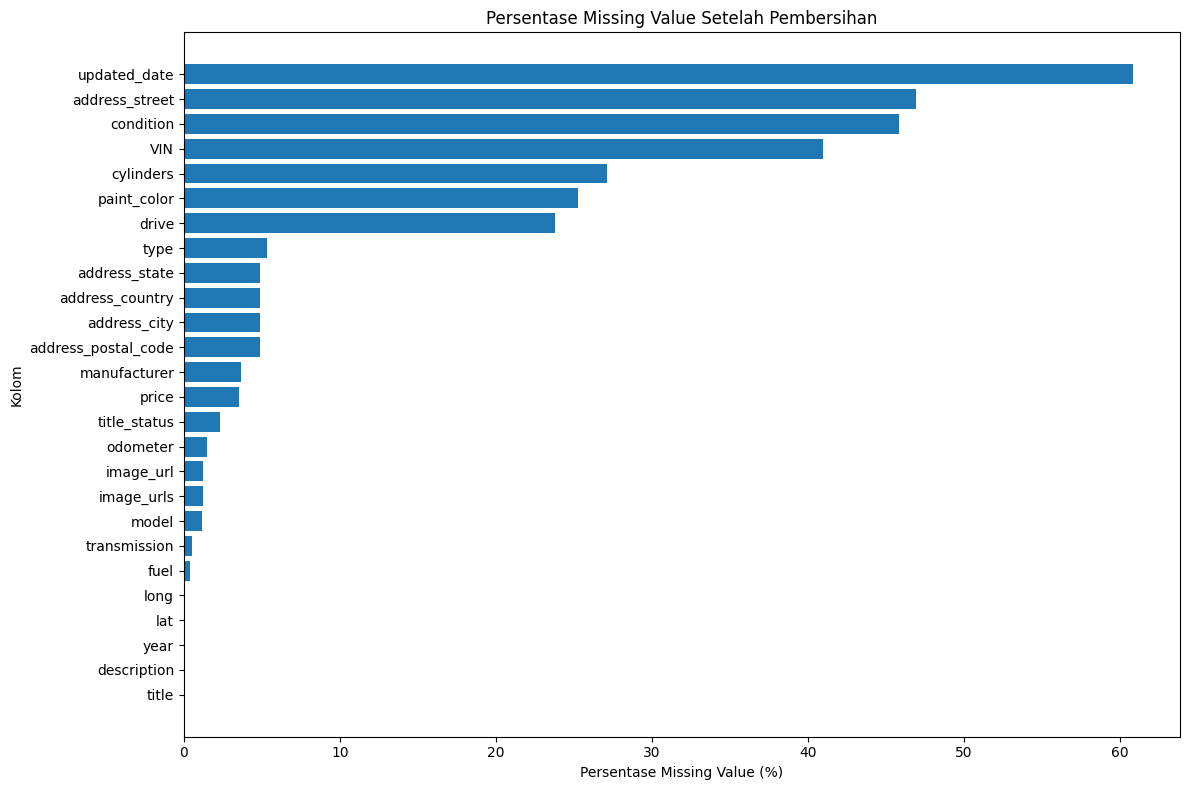

In [79]:
import matplotlib.pyplot as plt

missing_data = missing_summary[
    missing_summary['Missing Value'] > 0
]

plt.figure(figsize=(12, 8))

plt.barh(
    missing_data.index,
    missing_data['Persentase (%)']
)

plt.xlabel('Persentase Missing Value (%)')
plt.ylabel('Kolom')
plt.title('Persentase Missing Value Setelah Pembersihan')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [80]:
# Kolom yang tidak digunakan
kolom_dihapus = [
    'updated_date',
    'address_street'
]

# Menghapus kolom dari dataset
df_clean = df_clean.drop(columns=kolom_dihapus)

print("Kolom dihapus:", kolom_dihapus)
print("Ukuran dataset:", df_clean.shape)

Kolom dihapus: ['updated_date', 'address_street']
Ukuran dataset: (295451, 35)


In [81]:
# Kolom kategorikal yang akan diisi Unknown
kolom_kategorikal = [
    'condition',
    'cylinders',
    'paint_color',
    'drive',
    'type',
    'manufacturer',
    'transmission',
    'fuel',
    'title_status'
]

# Mengisi missing value dengan Unknown
for kolom in kolom_kategorikal:
    df_clean[kolom] = df_clean[kolom].fillna('Unknown')

print("Pengisian missing value kategorikal selesai.")

display(df_clean[kolom_kategorikal].isnull().sum())

Pengisian missing value kategorikal selesai.


,0
condition,0
cylinders,0
paint_color,0
drive,0
type,0
manufacturer,0
transmission,0
fuel,0
title_status,0


In [82]:
# Rekapitulasi missing value setelah pengisian kategorikal
missing_akhir = pd.DataFrame({
    'Missing Value': df_clean.isnull().sum(),
    'Persentase (%)': (
        df_clean.isnull().sum() / len(df_clean) * 100
    )
})

missing_akhir = missing_akhir[
    missing_akhir['Missing Value'] > 0
].sort_values(
    by='Persentase (%)',
    ascending=False
)

display(missing_akhir)

print("Total kolom dengan missing value:",
      len(missing_akhir))


,Missing Value,Persentase (%)
VIN,121119,40.994615
address_country,14471,4.897936
address_city,14471,4.897936
address_state,14471,4.897936
address_postal_code,14471,4.897936
price,10359,3.506165
odometer,4323,1.463187
image_urls,3538,1.197491
image_url,3538,1.197491
model,3359,1.136906


Total kolom dengan missing value: 15


In [83]:
# Memeriksa tipe data setelah proses cleaning
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 295451 entries, 0 to 295450
Data columns (total 35 columns):
 #   Column                Non-Null Count   Dtype              
---  ------                --------------   -----              
 0   id                    295451 non-null  int64              
 1   url                   295451 non-null  object             
 2   region                295451 non-null  object             
 3   region_url            295451 non-null  object             
 4   price                 285092 non-null  float64            
 5   year                  295411 non-null  float64            
 6   manufacturer          295451 non-null  object             
 7   model                 292092 non-null  object             
 8   condition             295451 non-null  object             
 9   cylinders             295451 non-null  object             
 10  fuel                  295451 non-null  object             
 11  odometer              291128 non-null  float64      

In [84]:
# Memeriksa konsistensi latitude dan longitude

lat_kosong = df_clean['lat'].isna()
long_kosong = df_clean['long'].isna()

print("Latitude kosong:", lat_kosong.sum())
print("Longitude kosong:", long_kosong.sum())

print("Latitude dan longitude sama-sama kosong:",
      (lat_kosong & long_kosong).sum())

print("Hanya latitude yang kosong:",
      (lat_kosong & ~long_kosong).sum())

print("Hanya longitude yang kosong:",
      (~lat_kosong & long_kosong).sum())

Latitude kosong: 149
Longitude kosong: 149
Latitude dan longitude sama-sama kosong: 149
Hanya latitude yang kosong: 0
Hanya longitude yang kosong: 0


In [85]:
# Membandingkan isi kedua kolom gambar

gambar_sama = (
    df_clean['image_url'].fillna('MISSING') ==
    df_clean['image_urls'].fillna('MISSING')
)

print("Jumlah isi kedua kolom yang sama:",
      gambar_sama.sum())

print("Jumlah isi kedua kolom yang berbeda:",
      (~gambar_sama).sum())


Jumlah isi kedua kolom yang sama: 6947
Jumlah isi kedua kolom yang berbeda: 288504


In [86]:
print("Jumlah duplikasi seluruh baris:",
      df_clean.duplicated().sum())

print("Jumlah duplikasi ID:",
      df_clean['id'].duplicated().sum())


Jumlah duplikasi seluruh baris: 0
Jumlah duplikasi ID: 0


In [87]:
# Mengambil 10 data yang memiliki kedua URL gambar
contoh_gambar = df_clean[
    df_clean['image_url'].notna() &
    df_clean['image_urls'].notna()
][['id', 'image_url', 'image_urls']].head(10)

display(contoh_gambar)

,id,image_url,image_urls
0,7994372850,https://images.craigslist.org/00N0N_aBzbdTBI4c...,https://images.craigslist.org/00N0N_aBzbdTBI4c...
1,7994372787,https://images.craigslist.org/00n0n_gNzbApFpKG...,https://images.craigslist.org/00n0n_gNzbApFpKG...
2,7994372559,https://images.craigslist.org/00Z0Z_3KNlCaCAM2...,https://images.craigslist.org/00Z0Z_3KNlCaCAM2...
3,7994372553,https://images.craigslist.org/00s0s_4aCpejyeUW...,https://images.craigslist.org/00s0s_4aCpejyeUW...
4,7994372166,https://images.craigslist.org/00T0T_4wec2Grzn3...,https://images.craigslist.org/00T0T_4wec2Grzn3...
5,7994371791,https://images.craigslist.org/00Q0Q_3Cqd9vJBwR...,https://images.craigslist.org/00Q0Q_3Cqd9vJBwR...
6,7994371425,https://images.craigslist.org/00g0g_kNWIfqMU0u...,https://images.craigslist.org/00g0g_kNWIfqMU0u...
7,7994370954,https://images.craigslist.org/00R0R_3stFFo19s4...,https://images.craigslist.org/00R0R_3stFFo19s4...
8,7994370897,https://images.craigslist.org/00o0o_7HYTUzx4fB...,https://images.craigslist.org/00o0o_7HYTUzx4fB...
9,7994370462,https://images.craigslist.org/00u0u_eut02J8jf1...,https://images.craigslist.org/00u0u_eut02J8jf1...


In [88]:
print("Tipe data image_url:")
print(df_clean['image_url'].apply(type).value_counts())

print("\nTipe data image_urls:")
print(df_clean['image_urls'].apply(type).value_counts())

Tipe data image_url:
image_url
<class 'str'>      291913
<class 'float'>      3538
Name: count, dtype: int64

Tipe data image_urls:
image_urls
<class 'str'>      291913
<class 'float'>      3538
Name: count, dtype: int64


In [89]:
# Mengambil contoh data yang memiliki isi berbeda
gambar_berbeda = df_clean[
    df_clean['image_url'].notna() &
    df_clean['image_urls'].notna() &
    (df_clean['image_url'] != df_clean['image_urls'])
][['id', 'image_url', 'image_urls']].head(5)

for _, row in gambar_berbeda.iterrows():
    print("ID:", row['id'])

    print("\nimage_url:")
    print(repr(row['image_url']))

    print("\nimage_urls:")
    print(repr(row['image_urls']))

    print("\nPanjang image_url:", len(row['image_url']))
    print("Panjang image_urls:", len(row['image_urls']))

    print("-" * 80)

ID: 7994372850

image_url:
'https://images.craigslist.org/00N0N_aBzbdTBI4cO_0eI0b0_600x450.jpg'

image_urls:
'https://images.craigslist.org/00N0N_aBzbdTBI4cO_0eI0b0_600x450.jpg https://images.craigslist.org/00I0I_6ljPV7IxGVd_0eI0b0_600x450.jpg https://images.craigslist.org/00202_53b3EWud0Zo_0eI0b0_600x450.jpg https://images.craigslist.org/00E0E_apwFxXMaKh7_0eI0b0_600x450.jpg https://images.craigslist.org/00F0F_3XAZblptREf_0eI0b0_600x450.jpg https://images.craigslist.org/00r0r_lfyQKdObk8X_0eI0b0_600x450.jpg https://images.craigslist.org/01616_fcxfOahSZn7_0eI0b0_600x450.jpg https://images.craigslist.org/00606_qvjVBloT5n_0eI0b0_600x450.jpg https://images.craigslist.org/01414_ffszmin8mDg_0eI0b0_600x450.jpg https://images.craigslist.org/00k0k_dp07xorYKrt_0eI0b0_600x450.jpg https://images.craigslist.org/00D0D_k6r99N86n93_0eI0b0_600x450.jpg https://images.craigslist.org/01717_aYCY4V1DyWw_0eI0b0_600x450.jpg https://images.craigslist.org/00m0m_8FPooiRbupL_0eI0b0_600x450.jpg https://images.craig

In [90]:
# Membuat salinan dataset final
df_final = df_clean.copy()

print("Dataset final berhasil dibuat!")
print("Jumlah baris:", df_final.shape[0])
print("Jumlah kolom:", df_final.shape[1])

Dataset final berhasil dibuat!
Jumlah baris: 295451
Jumlah kolom: 35


In [91]:
print("===== VALIDASI DATASET FINAL =====")

print("\n1. Ukuran dataset:")
print(df_final.shape)

print("\n2. Duplikasi seluruh baris:")
print(df_final.duplicated().sum())

print("\n3. Duplikasi ID:")
print(df_final['id'].duplicated().sum())

print("\n4. Total missing value:")
print(df_final.isnull().sum().sum())

print("\n5. Missing value per kolom:")
display(
    df_final.isnull().sum()[df_final.isnull().sum() > 0]
)

print("\n6. Informasi tipe data:")
df_final.info()

===== VALIDASI DATASET FINAL =====

1. Ukuran dataset:
(295451, 35)

2. Duplikasi seluruh baris:
0

3. Duplikasi ID:
0

4. Total missing value:
204469

5. Missing value per kolom:


,0
price,10359
year,40
model,3359
odometer,4323
VIN,121119
image_url,3538
description,6
lat,149
long,149
title,5



6. Informasi tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 295451 entries, 0 to 295450
Data columns (total 35 columns):
 #   Column                Non-Null Count   Dtype              
---  ------                --------------   -----              
 0   id                    295451 non-null  int64              
 1   url                   295451 non-null  object             
 2   region                295451 non-null  object             
 3   region_url            295451 non-null  object             
 4   price                 285092 non-null  float64            
 5   year                  295411 non-null  float64            
 6   manufacturer          295451 non-null  object             
 7   model                 292092 non-null  object             
 8   condition             295451 non-null  object             
 9   cylinders             295451 non-null  object             
 10  fuel                  295451 non-null  object             
 11  odometer              29112

In [92]:
import os
# Menyimpan dataset final (mendukung Colab & Lokal)
output_dir = '/content/datasets' if os.path.exists('/content/datasets') else '.'
output_file = os.path.join(output_dir, 'vehicles_cleaned.csv')

df_final.to_csv(
    output_file,
    index=False
)

print(f"Dataset final berhasil disimpan ke: {output_file}!")


Dataset final berhasil disimpan!


#Step 7 — Memuat Dataset Bersih & Analisis Lanjutan


In [93]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Memuat dataset hasil Data Processing (mendukung Colab & Lokal)
clean_candidates = ['/content/datasets/vehicles_cleaned.csv', 'vehicles_cleaned.csv', 'datasets/vehicles_cleaned.csv']
clean_path = next((p for p in clean_candidates if os.path.exists(p)), '/content/datasets/vehicles_cleaned.csv')

df_final = pd.read_csv(
    clean_path,
    low_memory=False
)

print(f"Ukuran dataset: {df_final.shape} (dimuat dari {clean_path})")
display(df_final.head())


/tmp/ipykernel_879/4118098398.py:7: DtypeWarning: Columns (28) have mixed types. Specify dtype option on import or set low_memory=False.
  df_final = pd.read_csv(


Ukuran dataset: (295451, 35)


,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,type,paint_color,image_url,description,state,lat,long,posting_date,seller_type,title,address_city,address_state,address_postal_code,address_country,image_count,image_urls,delivery_available,odometer_broken,odometer_rolled_over
0,7994372850,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,27999.0,2022.0,ford,explorer st,excellent,6 cylinders,gas,99179.0,clean,automatic,1FM5K8GCXNGA77516,4wd,SUV,grey,https://images.craigslist.org/00N0N_aBzbdTBI4c...,⭐ Autorace ⭐ 🏷️ STOCK #: 1726 📞 CALL OR TEXT: ...,ca,37.371435,-122.047863,2026-11-03 03:24:16+00:00,dealer,2022 Ford Explorer ST,Sunnyvale,CA,94088,US,20,https://images.craigslist.org/00N0N_aBzbdTBI4c...,0,0,0
1,7994372787,https://sfbay.craigslist.org/cto/d/mill-valley...,SF bay area,https://sfbay.craigslist.org,2200.0,1969.0,volkswagen,bug,fair,4 cylinders,gas,90000.0,clean,manual,NaN,rwd,other,green,https://images.craigslist.org/00n0n_gNzbApFpKG...,I am selling a 1969Vw Bug all original. This i...,ca,37.906000,-122.545000,2026-11-03 03:23:52+00:00,owner,69 VW Bug All Original Runs and drives current...,Mill Valley,CA,94942,US,4,https://images.craigslist.org/00n0n_gNzbApFpKG...,0,0,0
2,7994372559,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,15999.0,2016.0,rover,sport,excellent,6 cylinders,gas,82896.0,clean,automatic,SALWR2VF6GA636931,4wd,SUV,white,https://images.craigslist.org/00Z0Z_3KNlCaCAM2...,⭐ Autorace ⭐ 🏷️ STOCK #: 1544 📞 CALL OR TEXT: ...,ca,37.371435,-122.047863,2026-11-03 03:22:44+00:00,dealer,2016 Land Rover Range Rover Sport 3.0L V6 Supe...,Sunnyvale,CA,94088,US,20,https://images.craigslist.org/00Z0Z_3KNlCaCAM2...,0,0,0
3,7994372553,https://sfbay.craigslist.org/cto/d/napa-1974-c...,SF bay area,https://sfbay.craigslist.org,12000.0,1974.0,cadillac,eldorado convertible,good,8 cylinders,gas,89687.0,clean,automatic,NaN,fwd,convertible,blue,https://images.craigslist.org/00s0s_4aCpejyeUW...,Reluctantly posting this beauty for sale after...,ca,38.321878,-122.306027,2026-11-03 03:22:42+00:00,owner,1974 Cadillac Eldorado Convertible,Napa,CA,94581,US,8,https://images.craigslist.org/00s0s_4aCpejyeUW...,0,0,0
4,7994372166,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,18999.0,2009.0,dodge,challenger lc srt8,excellent,8 cylinders,gas,81724.0,clean,automatic,2B3LJ74W39H549395,rwd,coupe,orange,https://images.craigslist.org/00T0T_4wec2Grzn3...,⭐ Autorace ⭐ 🏷️ STOCK #: 1621 📞 CALL OR TEXT: ...,ca,37.371435,-122.047863,2026-11-03 03:21:10+00:00,dealer,2009 Dodge Challenger SRT8,Sunnyvale,CA,94088,US,20,https://images.craigslist.org/00T0T_4wec2Grzn3...,0,0,0


In [94]:
# Statistik deskriptif harga kendaraan
print("Statistik Harga Kendaraan")
display(df_final['price'].describe())

# Menghitung persentil harga
print("\nPersentil Harga:")
display(
    df_final['price'].quantile(
        [0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999]
    )
)

# Menghitung jumlah missing value
print("\nMissing Value:", df_final['price'].isna().sum())

Statistik Harga Kendaraan


,price
count,285092.000000
mean,18313.384813
std,20541.063017
min,1.000000
25%,6950.000000
50%,12995.000000
75%,22995.000000
max,1000000.000000



Persentil Harga:


,price
0.250,6950.0
0.500,12995.0
0.750,22995.0
0.900,37985.0
0.950,49997.0
0.990,89900.0
0.995,110000.0
0.999,219995.0



Missing Value: 10359


Jumlah data untuk visualisasi: 282257
Batas persentil 99: 89900.0


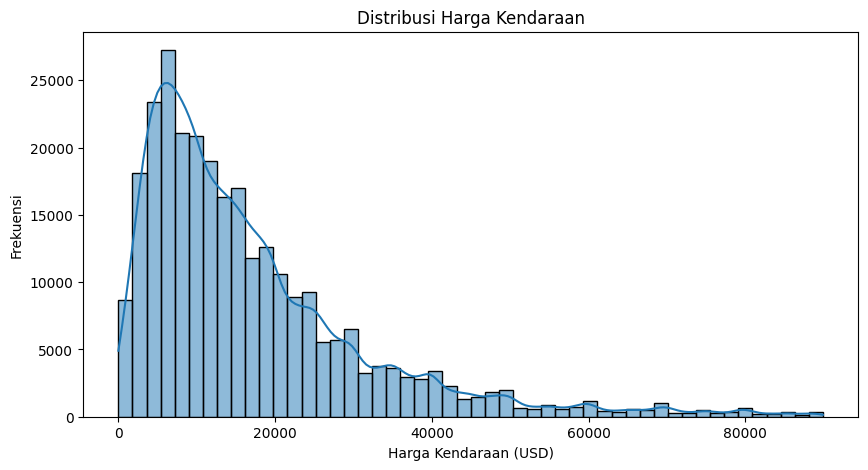

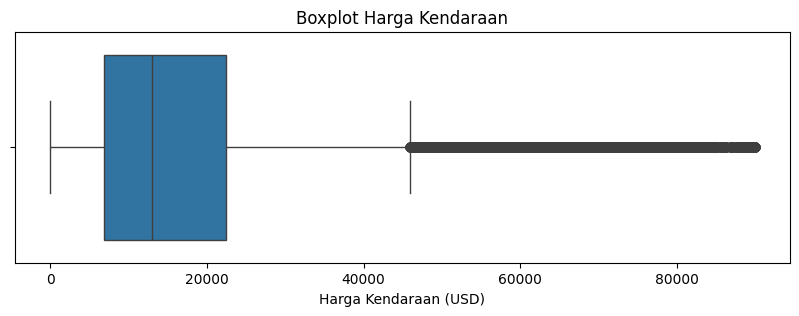

In [95]:
# Mengambil harga yang valid
price_data = df_final[
    df_final['price'].notna() &
    (df_final['price'] > 0)
]['price']

# Menghitung batas persentil 99
price_p99 = price_data.quantile(0.99)

# Data khusus visualisasi
price_viz = price_data[price_data <= price_p99]

print("Jumlah data untuk visualisasi:", len(price_viz))
print("Batas persentil 99:", price_p99)

# Histogram
plt.figure(figsize=(10, 5))
sns.histplot(price_viz, bins=50, kde=True)

plt.title('Distribusi Harga Kendaraan')
plt.xlabel('Harga Kendaraan (USD)')
plt.ylabel('Frekuensi')
plt.show()

# Boxplot
plt.figure(figsize=(10, 3))
sns.boxplot(x=price_viz)

plt.title('Boxplot Harga Kendaraan')
plt.xlabel('Harga Kendaraan (USD)')
plt.show()

Berdasarkan hasil analisis distribusi harga kendaraan pada dataset yang telah melalui tahap Data Processing, diperoleh 285.092 data harga yang valid. Harga kendaraan memiliki nilai rata-rata sebesar $18.313,38 dan median sebesar $12.995. Sebanyak 50% kendaraan memiliki harga dalam rentang $6.950  
  $22.995.

Visualisasi histogram menunjukkan bahwa distribusi harga kendaraan memiliki pola right-skewed, yaitu sebagian besar kendaraan berada pada rentang harga yang relatif rendah, sedangkan jumlah kendaraan dengan harga tinggi semakin sedikit. Nilai rata-rata yang lebih tinggi dibandingkan median juga memperkuat indikasi adanya sejumlah kendaraan dengan harga tinggi.

Dengan demikian, harga kendaraan dalam dataset cenderung terkonsentrasi pada rentang harga menengah ke bawah, dengan sebagian kecil kendaraan memiliki harga yang jauh lebih tinggi.

In [96]:
# Mengambil kolom yang dibutuhkan
q2_data = df_final[['year', 'odometer', 'price']].copy()

# Membatasi data untuk visualisasi dan analisis
q2_viz = q2_data[
    (q2_data['price'] > 0) &
    (q2_data['price'] <= q2_data['price'].quantile(0.99)) &
    (q2_data['odometer'] > 0) &
    (q2_data['odometer'] <= q2_data['odometer'].quantile(0.99)) &
    (q2_data['year'] <= 2026)
].dropna()

print("Jumlah data Q2:", len(q2_viz))
display(q2_viz.describe())

Jumlah data Q2: 275254


,year,odometer,price
count,275254.000000,275254.000000,275254.000000
mean,2012.676161,110070.738405,16991.012937
std,11.305715,57818.726791,14604.950396
min,1901.000000,1.000000,1.000000
25%,2010.000000,69893.250000,6900.000000
50%,2015.000000,108534.500000,12950.000000
75%,2019.000000,147180.000000,22245.000000
max,2026.000000,290000.000000,89900.000000


In [97]:
# Korelasi Pearson
corr_pearson = q2_viz[['year', 'odometer', 'price']].corr(
    method='pearson'
)

print("Korelasi Pearson:")
display(corr_pearson)

# Korelasi Spearman
corr_spearman = q2_viz[['year', 'odometer', 'price']].corr(
    method='spearman'
)

print("Korelasi Spearman:")
display(corr_spearman)

Korelasi Pearson:


,year,odometer,price
year,1.000000,-0.137863,0.208928
odometer,-0.137863,1.000000,-0.496442
price,0.208928,-0.496442,1.000000


Korelasi Spearman:


,year,odometer,price
year,1.000000,-0.424110,0.523254
odometer,-0.424110,1.000000,-0.538286
price,0.523254,-0.538286,1.000000


1. Interpretasi korelasi Pearson
Pearson digunakan untuk mengukur kekuatan dan arah hubungan linear antarvariabel.
Hubungan	Pearson	Interpretasi
Year – Odometer	-0,138	Negatif sangat lemah
Year – Price	+0,209	Positif lemah
Odometer – Price	-0,496	Negatif sedang

Penjelasan:
- Year – Odometer (-0,138): Hubungan negatif sangat lemah. Tahun kendaraan yang lebih baru cenderung memiliki odometer lebih rendah, tetapi hubungannya tidak terlalu kuat.
- Year – Price (+0,209): Hubungan positif lemah. Kendaraan dengan tahun produksi lebih baru cenderung memiliki harga lebih tinggi.
- Odometer – Price (-0,496): Hubungan negatif sedang. Semakin tinggi jarak tempuh kendaraan, harga cenderung semakin rendah.
2. Interpretasi korelasi Spearman
Spearman mengukur hubungan berdasarkan peringkat (rank), sehingga dapat mendeteksi hubungan monotonik yang tidak harus linear.
Hubungan	Spearman	Interpretasi
Year – Odometer	-0,424	Negatif sedang
Year – Price	+0,523	Positif sedang
Odometer – Price	-0,538	Negatif sedang

Penjelasan:
- Year – Odometer (-0,424): Kendaraan yang lebih baru cenderung memiliki jarak tempuh lebih rendah.
- Year – Price (+0,523): Kendaraan yang lebih baru cenderung memiliki harga lebih tinggi.
- Odometer – Price (-0,538): Kendaraan dengan jarak tempuh lebih tinggi cenderung memiliki harga lebih rendah.

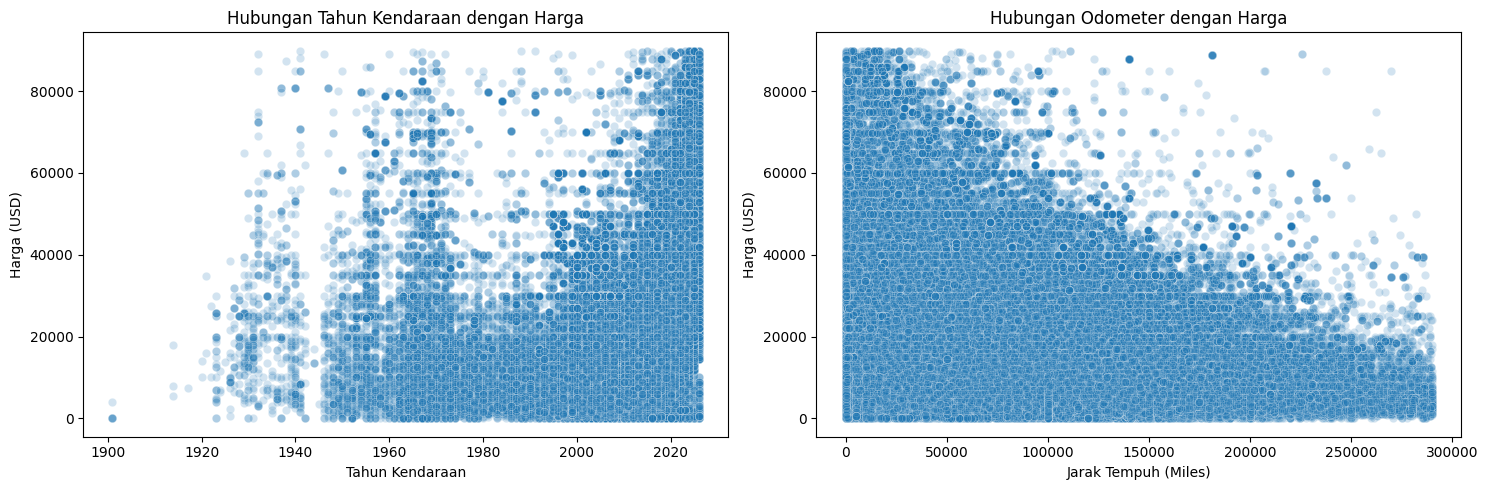

In [98]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Tahun kendaraan vs harga
sns.scatterplot(
    data=q2_viz,
    x='year',
    y='price',
    alpha=0.2,
    ax=axes[0]
)
axes[0].set_title('Hubungan Tahun Kendaraan dengan Harga')
axes[0].set_xlabel('Tahun Kendaraan')
axes[0].set_ylabel('Harga (USD)')

# Odometer vs harga
sns.scatterplot(
    data=q2_viz,
    x='odometer',
    y='price',
    alpha=0.2,
    ax=axes[1]
)
axes[1].set_title('Hubungan Odometer dengan Harga')
axes[1].set_xlabel('Jarak Tempuh (Miles)')
axes[1].set_ylabel('Harga (USD)')

plt.tight_layout()
plt.show()

A. Tahun kendaraan vs harga
- Titik-titik menunjukkan kecenderungan harga lebih tinggi pada kendaraan dengan tahun produksi lebih baru.
- Kendaraan dengan tahun produksi lama umumnya memiliki harga lebih rendah.
- Namun, variasi harga masih cukup besar pada setiap tahun produksi.
Hal ini mendukung korelasi positif antara tahun kendaraan dan harga.

B. Odometer vs harga
- Kendaraan dengan jarak tempuh rendah memiliki rentang harga yang sangat bervariasi.
- Semakin tinggi jarak tempuh, titik-titik cenderung terkonsentrasi pada harga yang lebih rendah.
- Hal ini mendukung korelasi negatif antara odometer dan ha

In [99]:
# Memeriksa kendaraan dengan tahun produksi 1901
year_1901 = df_final[df_final['year'] == 1901]

print("Jumlah kendaraan tahun 1901:", len(year_1901))

display(
    year_1901[
        ['id', 'manufacturer', 'model', 'year', 'title', 'description']
    ].head(10)
)


Jumlah kendaraan tahun 1901: 6


,id,manufacturer,model,year,title,description
50320,7975453560,Unknown,oldsmobile,1901.0,1901 Oldsmobile Curved Dash,FOR SALE-- $4000. Or Best Offer-- 1901 Oldsmob...
195991,7985715081,Unknown,NaN,1901.0,NaN,NaN
197286,7984818315,Unknown,NaN,1901.0,NaN,NaN
198465,7983924975,Unknown,NaN,1901.0,NaN,NaN
203001,7980029856,Unknown,NaN,1901.0,NaN,NaN
208332,7975361838,Unknown,NaN,1901.0,NaN,NaN


Berdasarkan analisis terhadap 275.254 data kendaraan, ditemukan bahwa tahun produksi, jarak tempuh, dan harga kendaraan memiliki hubungan dengan tingkat kekuatan yang berbeda. Hasil korelasi Pearson menunjukkan hubungan positif lemah antara tahun produksi dan harga kendaraan sebesar 0,209, serta hubungan negatif sedang antara jarak tempuh dan harga kendaraan sebesar -0,496.

Sementara itu, hasil korelasi Spearman menunjukkan hubungan positif sedang antara tahun produksi dan harga sebesar 0,523, serta hubungan negatif sedang antara jarak tempuh dan harga sebesar -0,538. Hasil ini menunjukkan bahwa kendaraan dengan tahun produksi lebih baru cenderung memiliki harga lebih tinggi, sedangkan kendaraan dengan jarak tempuh lebih tinggi cenderung memiliki harga lebih rendah.

Visualisasi scatter plot mendukung temuan tersebut. Meskipun demikian, hubungan korelasi tidak menunjukkan hubungan sebab-akibat. Harga kendaraan juga dapat dipengaruhi oleh faktor lain, seperti manufacturer, kondisi kendaraan, dan jenis bahan bakar.

In [100]:
# Mengambil kolom yang diperlukan
q3_data = df_final[
    ['manufacturer', 'fuel', 'transmission', 'price']
].copy()

# Mengambil data dengan harga valid
q3_data = q3_data[
    q3_data['price'].notna() &
    (q3_data['price'] > 0)
]

# Membatasi harga sampai persentil ke-99 untuk analisis visual
price_p99 = q3_data['price'].quantile(0.99)

q3_viz = q3_data[
    q3_data['price'] <= price_p99
].copy()

print("Jumlah data Q3:", len(q3_viz))
print("Batas harga persentil ke-99:", price_p99)

display(q3_viz.describe(include='all'))

Jumlah data Q3: 282257
Batas harga persentil ke-99: 89900.0


,manufacturer,fuel,transmission,price
count,282257,282257,282257,282257.000000
unique,43,6,4,NaN
top,ford,gas,automatic,NaN
freq,48764,239608,255010,NaN
mean,NaN,NaN,NaN,17107.770291
std,NaN,NaN,NaN,14826.255966
min,NaN,NaN,NaN,1.000000
25%,NaN,NaN,NaN,6900.000000
50%,NaN,NaN,NaN,12980.000000
75%,NaN,NaN,NaN,22500.000000


In [101]:
# 10 manufacturer dengan jumlah listing terbanyak
top_manufacturers = q3_viz['manufacturer'].value_counts().head(10).index

manufacturer_stats = (
    q3_viz[q3_viz['manufacturer'].isin(top_manufacturers)]
    .groupby('manufacturer')['price']
    .agg(['count', 'median', 'mean'])
    .sort_values('median', ascending=False)
)

print("Statistik Harga Berdasarkan Manufacturer:")
display(manufacturer_stats.round(2))


# Statistik berdasarkan jenis bahan bakar
fuel_stats = (
    q3_viz.groupby('fuel')['price']
    .agg(['count', 'median', 'mean'])
    .sort_values('median', ascending=False)
)

print("\nStatistik Harga Berdasarkan Fuel:")
display(fuel_stats.round(2))


# Statistik berdasarkan jenis transmisi
transmission_stats = (
    q3_viz.groupby('transmission')['price']
    .agg(['count', 'median', 'mean'])
    .sort_values('median', ascending=False)
)

print("\nStatistik Harga Berdasarkan Transmission:")
display(transmission_stats.round(2))

Statistik Harga Berdasarkan Manufacturer:


,count,median,mean
manufacturer,,,
ram,13813,23450.0,26594.60
gmc,10161,18985.0,25401.31
ford,48764,15000.0,20390.01
toyota,26096,14995.0,17967.91
chevrolet,32449,13950.0,17761.34
Unknown,9993,13800.0,19953.52
jeep,13029,12626.0,14352.35
honda,16754,11995.0,13725.77
subaru,10553,11490.0,12782.32



Statistik Harga Berdasarkan Fuel:


,count,median,mean
fuel,,,
diesel,23497,33900.0,34520.50
electric,4028,23499.5,25008.70
other,7314,21985.0,24670.24
hybrid,6805,18900.0,22783.95
Unknown,1005,15995.0,18848.13
gas,239608,11500.0,14868.03



Statistik Harga Berdasarkan Transmission:


,count,median,mean
transmission,,,
other,7364,19500.0,23544.01
Unknown,1464,15888.0,17347.49
manual,18419,13499.0,19293.78
automatic,255010,12800.0,16762.64


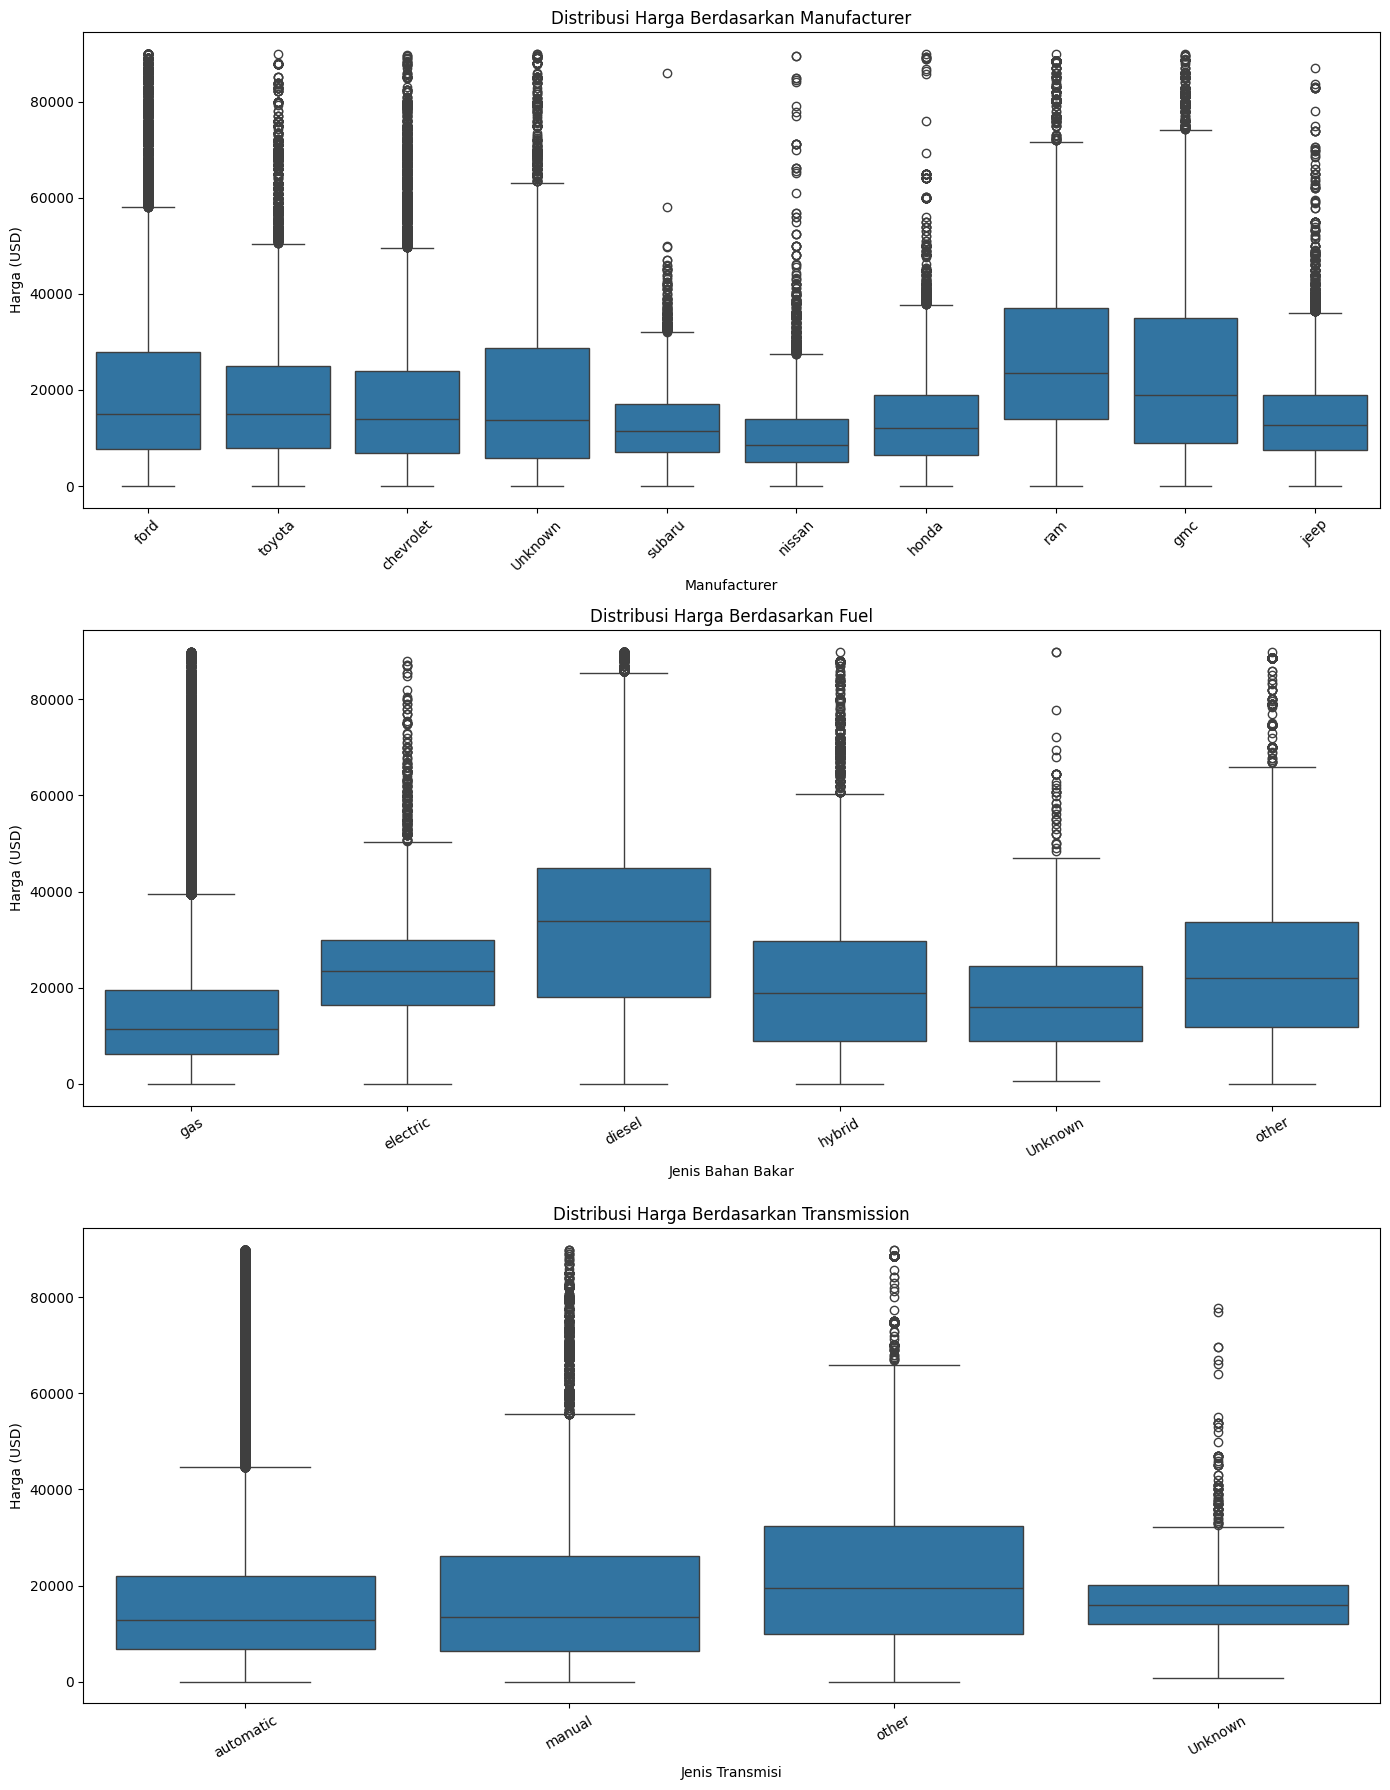

In [102]:
fig, axes = plt.subplots(3, 1, figsize=(14, 18))

# Manufacturer
sns.boxplot(
    data=q3_viz[q3_viz['manufacturer'].isin(top_manufacturers)],
    x='manufacturer',
    y='price',
    ax=axes[0]
)
axes[0].set_title('Distribusi Harga Berdasarkan Manufacturer')
axes[0].set_xlabel('Manufacturer')
axes[0].set_ylabel('Harga (USD)')
axes[0].tick_params(axis='x', rotation=45)

# Fuel
sns.boxplot(
    data=q3_viz,
    x='fuel',
    y='price',
    ax=axes[1]
)
axes[1].set_title('Distribusi Harga Berdasarkan Fuel')
axes[1].set_xlabel('Jenis Bahan Bakar')
axes[1].set_ylabel('Harga (USD)')
axes[1].tick_params(axis='x', rotation=30)

# Transmission
sns.boxplot(
    data=q3_viz,
    x='transmission',
    y='price',
    ax=axes[2]
)
axes[2].set_title('Distribusi Harga Berdasarkan Transmission')
axes[2].set_xlabel('Jenis Transmisi')
axes[2].set_ylabel('Harga (USD)')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

Berdasarkan analisis distribusi harga kendaraan berdasarkan manufacturer, fuel, dan transmission, ditemukan adanya perbedaan pola harga pada setiap kategori. Pada kategori manufacturer, RAM memiliki median harga tertinggi di antara sepuluh manufacturer dengan jumlah listing terbanyak, sedangkan Nissan memiliki median harga terendah.

Berdasarkan jenis bahan bakar, kendaraan diesel memiliki median harga tertinggi, diikuti oleh electric, sedangkan kendaraan berbahan bakar gas memiliki median harga terendah. Sementara itu, berdasarkan jenis transmisi, kategori Other memiliki median harga tertinggi, sedangkan automatic dan manual memiliki median harga yang relatif berdekatan.

Hasil boxplot juga menunjukkan adanya variasi harga dan sejumlah outlier pada setiap kategori. Hal ini menunjukkan bahwa harga kendaraan memiliki distribusi yang beragam berdasarkan merek, jenis bahan bakar, dan transmisi. Namun, hasil analisis ini hanya menunjukkan pola hubungan dalam dataset dan tidak membuktikan hubungan sebab-akibat.